<a href="https://colab.research.google.com/github/seema-2211/wsss/blob/main/WSSS_VOC2012_Complete_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Weakly-Supervised Semantic Segmentation (WSSS) on PASCAL VOC 2012
### CS747 · Cluster 3 · Topic 14 — CAM → Pseudo-masks → Refinement → Segmentation

**Goal:** train a segmentation network using **only image-level labels**, and compare it with a **fully-supervised** model trained on the *same* images.

This single notebook contains **every stage** of the project, built for a **small / free GPU** (Colab T4 16 GB, Kaggle P100/T4, or even 6-8 GB laptop GPUs).

| Stage | What | Project-guideline requirement |
|---|---|---|
| 0 | Environment, config presets (`DEBUG` / `LOW_GPU` / `FULL`) | – |
| 1-2 | Data download, image-level labels, EDA | Problem formulation |
| 3 | Datasets, metrics (mIoU, Dice, pixel-acc), training utilities | – |
| 4 | **Fully-supervised baseline** (upper bound) | Evaluation / comparison |
| 5 | Multi-label **classifier** (ResNet, stride-16) + LR hyper-parameter search | Hyper-parameters |
| 6 | **CAM** generation (multi-scale + flip) + cache | Methodology |
| 7 | **Pseudo-masks + refinement** (PAMR, optional DenseCRF, dual-threshold ignore band) + hyper-parameter selection | Methodology / HP |
| 8 | Train **WSSS segmentation** on pseudo-masks | Evaluation |
| 9 | **Our extension:** self-training round 2 | Own contribution |
| 10 | WSSS vs fully-supervised gap | Evaluation |
| 11 | **Ablations** (CAM scales, refinement, thresholds, ignore band, backbone, end-to-end) | Ablation studies |
| 12 | Qualitative visualisation, per-class IoU, curves, failure cases | Visualisation |
| 13 | SOTA / literature table + efficiency | SOTA comparison |
| 14 | Export CSV / LaTeX tables + figures for the **IEEE paper** | Findings |

### How to run with limited GPU
* Run **top-to-bottom**. Every long step **checkpoints** (to Google Drive on Colab) and **resumes** if the session dies.
* First run with `MODE = 'DEBUG'` (a few minutes) to verify the whole pipeline. Then switch to `LOW_GPU`.
* If you get **CUDA out of memory**: lower `cls_bs`, `seg_bs`, `cls_size`, `seg_size` in `PRESETS`, or use gradient accumulation (`ACCUM`).
* When you change `MODE` or any hyper-parameter, **delete old checkpoints** (or change the tag) — otherwise the resume logic reloads old results.

> **Honest-science note (put it in your paper):** the weak-supervision pipeline never reads pixel masks for *training*. Ground-truth masks of the train split are used **only** for (i) the fully-supervised baseline, and (ii) *diagnosing* pseudo-mask quality / choosing the CAM threshold on a small subset. Disclose (ii) in the paper.

## Stage 0 — Environment & configuration

In [ ]:
%pip install -q pandas scikit-learn matplotlib tqdm pyyaml

In [ ]:
import os, sys, json, time, math, random, shutil, tarfile, urllib.request, warnings
from pathlib import Path
from types import SimpleNamespace
import xml.etree.ElementTree as ET
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import average_precision_score
warnings.filterwarnings('ignore')

# ------------------------------------------------------------------
# 0.1  WHERE TO RUN / WHERE TO SAVE
# ------------------------------------------------------------------
IN_COLAB = 'google.colab' in sys.modules
USE_DRIVE = True          # Colab: persist checkpoints/results on Google Drive
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/wsss_project')
else:
    PROJECT_ROOT = Path(os.environ.get('WSSS_ROOT', './wsss_project'))
DATA_ROOT = Path(os.environ.get('WSSS_DATA', '/content/data' if IN_COLAB else str(PROJECT_ROOT / 'data')))
LOCAL     = Path('/content/work') if IN_COLAB else PROJECT_ROOT / 'work'   # regenerable (CAMs, pseudo-masks) -> fast local disk
CKPT = PROJECT_ROOT / 'checkpoints'
RES  = PROJECT_ROOT / 'results'
FIG, TAB, LOG = RES / 'figures', RES / 'tables', RES / 'logs'
for p in [PROJECT_ROOT, DATA_ROOT, LOCAL, CKPT, RES, FIG, TAB, LOG]:
    p.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------
# 0.2  PRESETS  (pick one)
# ------------------------------------------------------------------
MODE = 'LOW_GPU'     # 'DEBUG' (minutes, tiny subset) | 'LOW_GPU' (recommended) | 'FULL' (>=16GB GPU, best accuracy)

PRESETS = {
 'DEBUG':   dict(n_train=48,   n_val=24,   cls_size=224, cls_epochs=1,  cls_bs=8,  cls_arch='resnet50',
                 seg_size=224, seg_epochs=1,  seg_bs=4, seg_arch='mobilenet', abl_epochs=1, eval_every=1,
                 use_extra=False, hp_epochs=1, n_hp_imgs=24, n_abl_imgs=24),
 'LOW_GPU': dict(n_train=None, n_val=None, cls_size=320, cls_epochs=15, cls_bs=16, cls_arch='resnet50',
                 seg_size=320, seg_epochs=30, seg_bs=8, seg_arch='mobilenet', abl_epochs=30, eval_every=5,
                 use_extra=False, hp_epochs=3, n_hp_imgs=300, n_abl_imgs=300),
 'FULL':    dict(n_train=None, n_val=None, cls_size=448, cls_epochs=20, cls_bs=16, cls_arch='resnet50',
                 seg_size=448, seg_epochs=50, seg_bs=8, seg_arch='resnet50', abl_epochs=30, eval_every=5,
                 use_extra=True, hp_epochs=4, n_hp_imgs=500, n_abl_imgs=500),
}
C = SimpleNamespace(**PRESETS[MODE])
ACCUM = 1            # gradient accumulation steps for segmentation (raise to 2/4 if you must lower seg_bs further)
SEED = 42
NUM_WORKERS = int(os.environ.get('WSSS_WORKERS', 2))
RUN_HP_SWEEP = True            # classifier LR search (Stage 5)
RUN_ABL_SEG_TRAINING = True    # end-to-end ablations (Stage 11C) - the most expensive part; set False to skip

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'          # mixed precision = ~2x less memory, faster
torch.backends.cudnn.benchmark = False   # variable image sizes at eval time
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0), '| mem: %.1f GB' % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print('WARNING: no GPU found -> use MODE="DEBUG" or enable GPU runtime (Runtime > Change runtime type).')
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| MODE =', MODE)
print(C)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP)

def make_scaler():
    try:    return torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def clear_gpu():
    import gc; gc.collect()
    if device.type == 'cuda': torch.cuda.empty_cache()

# registry of every number that will go into the paper
RESULTS_PATH = RES / 'results.json'
RESULTS = json.load(open(RESULTS_PATH)) if RESULTS_PATH.exists() else {}
def record(key, value):
    RESULTS[key] = value
    json.dump(RESULTS, open(RESULTS_PATH, 'w'), indent=2, default=float)

def savefig(name):
    plt.savefig(FIG / f'{name}.png', dpi=200, bbox_inches='tight')

Mounted at /content/drive
GPU: Tesla T4 | mem: 15.6 GB
torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | MODE = LOW_GPU
namespace(n_train=None, n_val=None, cls_size=320, cls_epochs=15, cls_bs=16, cls_arch='resnet50', seg_size=320, seg_epochs=30, seg_bs=8, seg_arch='mobilenet', abl_epochs=30, eval_every=5, use_extra=False, hp_epochs=3, n_hp_imgs=300, n_abl_imgs=300)


## Stage 1 — PASCAL VOC 2012: download, splits, **image-level labels**

* Segmentation split: **1,464 train / 1,449 val** images. Val is used only for evaluation.
* **Image-level labels are parsed from the XML annotations** (object names only) — *not* from the pixel masks. This is exactly the weak supervision the problem statement allows.
* `use_extra=True` (FULL mode) additionally uses ~10k VOC images that have **no** segmentation mask, for **classifier training only** (more data -> better CAMs). Segmentation is still trained on the same 1,464 images as the baseline, so the comparison stays fair.

If the automatic download fails, download `VOCtrainval_11-May-2012.tar` manually (or from Kaggle: *"PASCAL VOC 2012"*), extract so that `DATA_ROOT/VOCdevkit/VOC2012/JPEGImages` exists.

In [ ]:
VOC_URLS = ['http://host.robots.ox.ac.uk/pascal/VOC/voc2012/VOCtrainval_11-May-2012.tar',
            'https://pjreddie.com/media/files/VOCtrainval_11-May-2012.tar']

def download_voc():
    if (DATA_ROOT / 'VOCdevkit' / 'VOC2012' / 'JPEGImages').exists():
        print('VOC2012 found at', DATA_ROOT); return
    tar_path = DATA_ROOT / 'VOCtrainval_11-May-2012.tar'
    ok = False
    for url in VOC_URLS:
        try:
            print('Downloading', url, '(~2 GB) ...'); urllib.request.urlretrieve(url, tar_path); ok = True; break
        except Exception as e:
            print('  failed:', e)
    if not ok:
        raise RuntimeError('Automatic download failed. Download the VOC2012 trainval tar manually and extract it into ' + str(DATA_ROOT))
    with tarfile.open(tar_path) as t: t.extractall(DATA_ROOT)
    tar_path.unlink()
download_voc()

VOC    = DATA_ROOT / 'VOCdevkit' / 'VOC2012'
JPEG   = VOC / 'JPEGImages'
SEGCLS = VOC / 'SegmentationClass'     # pixel masks: ONLY for baseline + evaluation
ANN    = VOC / 'Annotations'           # XML: source of image-level labels
SETS   = VOC / 'ImageSets'

CLASSES   = ['aeroplane','bicycle','bird','boat','bottle','bus','car','cat','chair','cow','diningtable','dog',
             'horse','motorbike','person','pottedplant','sheep','sofa','train','tvmonitor']
VOC_NAMES = ['background'] + CLASSES        # 21 segmentation classes

def read_ids(p): return [l.strip() for l in open(p) if l.strip()]
SEG_TRAIN = read_ids(SETS / 'Segmentation' / 'train.txt')
SEG_VAL   = read_ids(SETS / 'Segmentation' / 'val.txt')
MAIN_TV   = read_ids(SETS / 'Main' / 'trainval.txt') if (SETS / 'Main' / 'trainval.txt').exists() else []
_excl = set(SEG_TRAIN) | set(SEG_VAL)
EXTRA = [i for i in MAIN_TV if i not in _excl] if C.use_extra else []     # classifier-only images (never contain val images)

TRAIN_IDS = SEG_TRAIN[:C.n_train] if C.n_train else SEG_TRAIN
VAL_IDS   = SEG_VAL[:C.n_val]     if C.n_val   else SEG_VAL
CLS_TRAIN_IDS = TRAIN_IDS + EXTRA
print(f'seg-train {len(TRAIN_IDS)} | seg-val {len(VAL_IDS)} | extra classifier-only images {len(EXTRA)}')

# ---- image-level labels from XML (cached) ----
def parse_labels(i):
    root = ET.parse(ANN / f'{i}.xml').getroot()
    return sorted({CLASSES.index(o.find('name').text) for o in root.findall('object')})

LABEL_CACHE = PROJECT_ROOT / f'labels_cache_{MODE}.json'
LABELS = json.load(open(LABEL_CACHE)) if LABEL_CACHE.exists() else {}
need = [i for i in set(TRAIN_IDS) | set(VAL_IDS) | set(EXTRA) if i not in LABELS]
for i in tqdm(need, desc='parsing XML labels'): LABELS[i] = parse_labels(i)
json.dump(LABELS, open(LABEL_CACHE, 'w'))
print('example:', TRAIN_IDS[0], [CLASSES[c] for c in LABELS[TRAIN_IDS[0]]])

seg-train 1464 | seg-val 1449 | extra classifier-only images 0


parsing XML labels:   0%|          | 0/2913 [00:00<?, ?it/s]

example: 2007_000032 ['aeroplane', 'person']


## Stage 2 — Dataset exploration (feeds the *problem formulation* & *analysis* sections)
Class frequency, labels per image, and **class co-occurrence**. Co-occurrence matters: CAMs of frequently co-occurring classes (e.g. *person* with *horse/motorbike/chair*, *boat* with *water*) bleed into each other because the classifier can use context instead of the object itself.

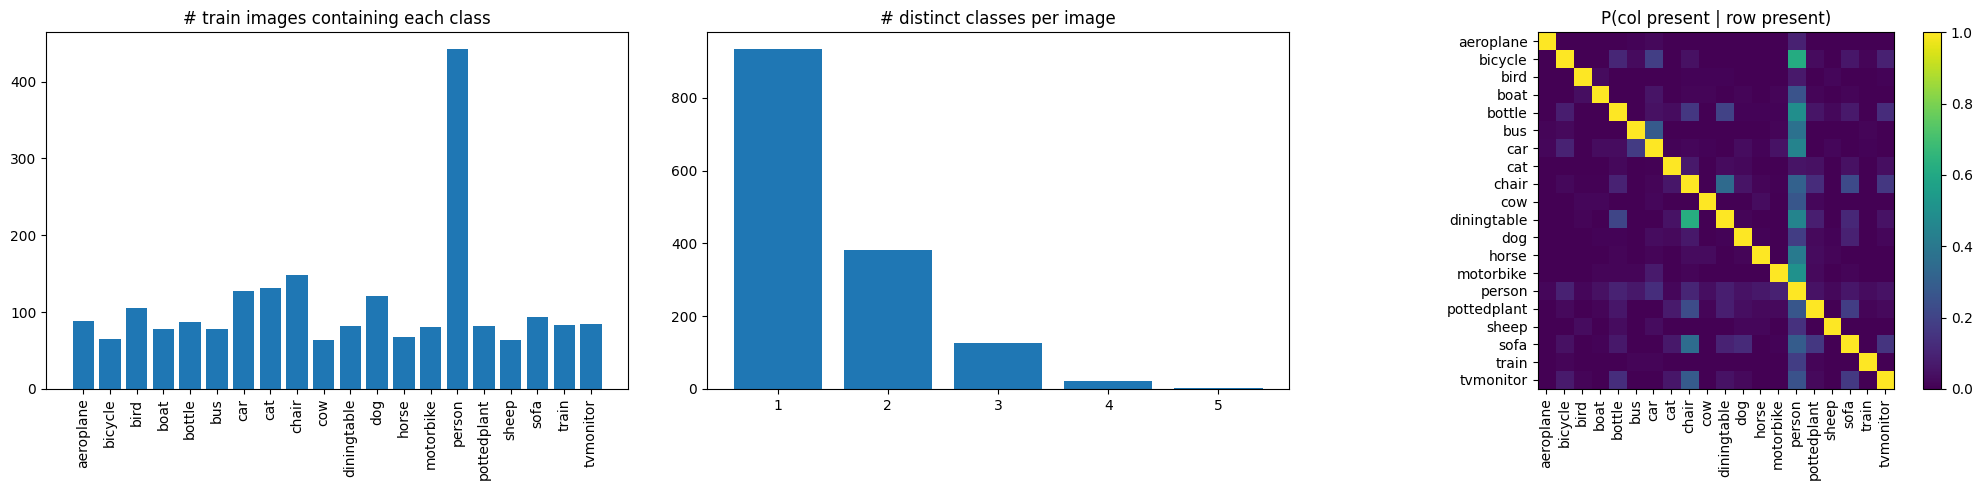

single-class images: 63.7%  |  mean classes/image: 1.48


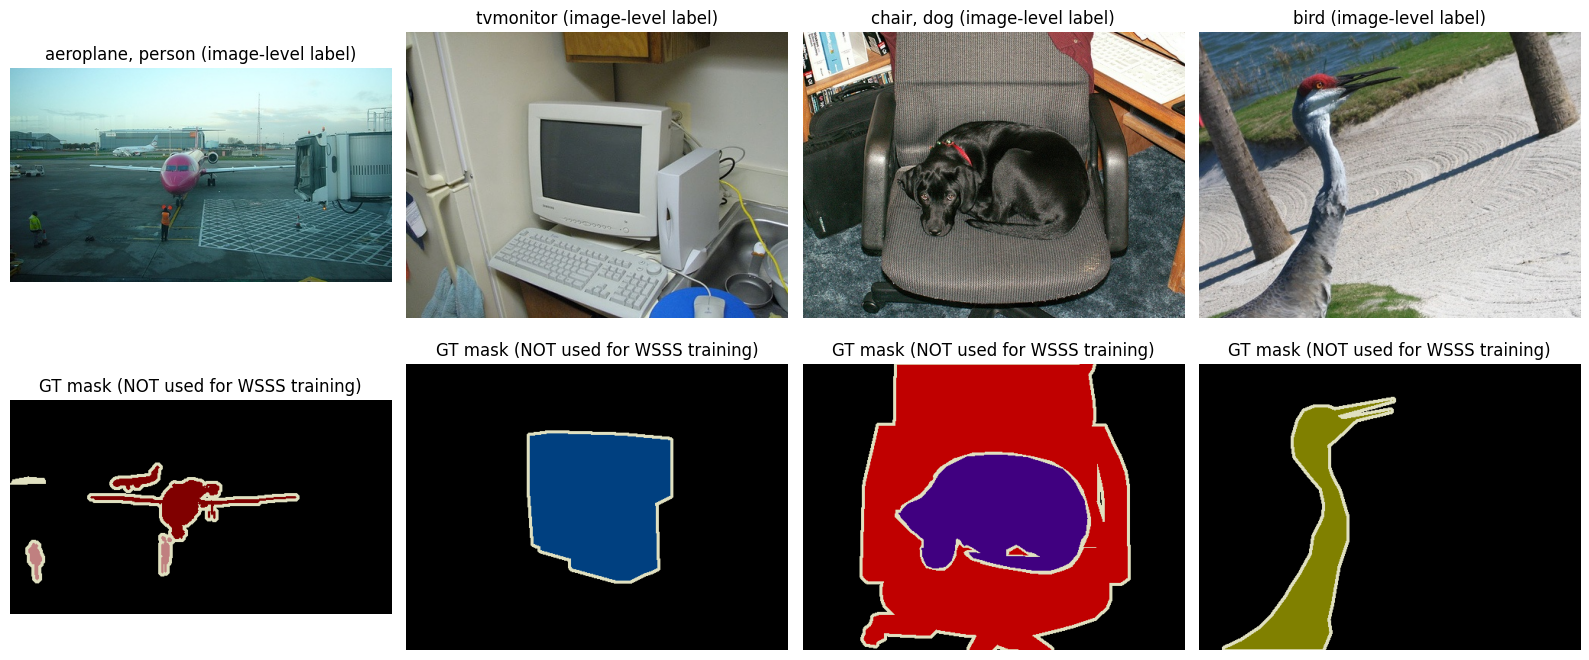

In [ ]:
def voc_cmap(N=256):
    def bit(v, i): return (v >> i) & 1
    cm = np.zeros((N, 3), np.uint8)
    for i in range(N):
        r = g = b = 0; c = i
        for j in range(8):
            r |= bit(c, 0) << (7 - j); g |= bit(c, 1) << (7 - j); b |= bit(c, 2) << (7 - j); c >>= 3
        cm[i] = [r, g, b]
    return cm
CMAP = voc_cmap()
def colorize(mask): return CMAP[mask]

def load_image(i): return Image.open(JPEG / f'{i}.jpg').convert('RGB')
def load_gt(i):    return np.array(Image.open(SEGCLS / f'{i}.png'))

cnt = np.zeros(20); co = np.zeros((20, 20))
for i in TRAIN_IDS:
    L = LABELS[i]
    for a in L:
        cnt[a] += 1
        for b in L: co[a, b] += 1
nlab = [len(LABELS[i]) for i in TRAIN_IDS]

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].bar(CLASSES, cnt); ax[0].set_xticklabels(CLASSES, rotation=90); ax[0].set_title('# train images containing each class')
ax[1].hist(nlab, bins=range(1, max(nlab) + 2), align='left', rwidth=.8); ax[1].set_title('# distinct classes per image')
co_n = co / np.maximum(np.diag(co)[:, None], 1)
im = ax[2].imshow(co_n, cmap='viridis'); ax[2].set_xticks(range(20)); ax[2].set_yticks(range(20))
ax[2].set_xticklabels(CLASSES, rotation=90); ax[2].set_yticklabels(CLASSES); ax[2].set_title('P(col present | row present)')
plt.colorbar(im, ax=ax[2], fraction=.046); plt.tight_layout(); savefig('eda_class_stats'); plt.show()
print(f'single-class images: {np.mean(np.array(nlab) == 1) * 100:.1f}%  |  mean classes/image: {np.mean(nlab):.2f}')

fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for k, i in enumerate(TRAIN_IDS[:4]):
    ax[0, k].imshow(load_image(i)); ax[0, k].set_title(', '.join(CLASSES[c] for c in LABELS[i]) + ' (image-level label)'); ax[0, k].axis('off')
    ax[1, k].imshow(colorize(load_gt(i))); ax[1, k].set_title('GT mask (NOT used for WSSS training)'); ax[1, k].axis('off')
plt.tight_layout(); savefig('eda_samples'); plt.show()

## Stage 3 — Datasets, metrics, training utilities

**Metrics** (computed from a 21x21 confusion matrix accumulated over the *whole* dataset — never average per-image IoUs):

$$IoU_c=\frac{TP_c}{TP_c+FP_c+FN_c},\quad mIoU=\frac1{N}\sum_c IoU_c,\quad Dice_c=\frac{2TP_c}{2TP_c+FP_c+FN_c},\quad PixAcc=\frac{\sum_c TP_c}{\#pixels}$$

Pixel accuracy alone is misleading on VOC (background is ~70 % of pixels), so **mIoU is the headline metric** (as required by the guidelines).

In [ ]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)
def normalize_np(img_u8):
    return ((img_u8.astype(np.float32) / 255. - MEAN) / STD).transpose(2, 0, 1)

def _canvas(shape, fill, dtype):
    c = np.empty(shape, dtype); c[...] = fill; return c

def scale_crop(img, mask, out_size, scale_range, hflip=True):
    """random scale -> pad (mean colour / 255 ignore) -> random crop -> random flip. img: PIL RGB, mask: uint8 array or None"""
    w, h = img.size
    s = random.uniform(*scale_range); nw, nh = max(int(w * s), 8), max(int(h * s), 8)
    img = np.array(img.resize((nw, nh), Image.BILINEAR))
    if mask is not None:
        mask = np.array(Image.fromarray(mask).resize((nw, nh), Image.NEAREST))
    H, W = max(nh, out_size), max(nw, out_size)
    ci = _canvas((H, W, 3), (MEAN * 255).astype(np.uint8), np.uint8); ci[:nh, :nw] = img
    cm = None
    if mask is not None:
        cm = _canvas((H, W), 255, np.uint8); cm[:nh, :nw] = mask
    y = random.randint(0, H - out_size); x = random.randint(0, W - out_size)
    ci = ci[y:y + out_size, x:x + out_size]
    if cm is not None: cm = cm[y:y + out_size, x:x + out_size]
    if hflip and random.random() < .5:
        ci = ci[:, ::-1]; cm = cm[:, ::-1] if cm is not None else None
    return np.ascontiguousarray(ci), (np.ascontiguousarray(cm) if cm is not None else None)

class SegDataset(Dataset):
    """mask_dir = SEGCLS (fully supervised) or a pseudo-mask folder (WSSS). 255 = ignore."""
    def __init__(self, ids, mask_dir, train, size=None):
        self.ids, self.mask_dir, self.train, self.size = ids, Path(mask_dir), train, size
        self.jit = T.ColorJitter(.3, .3, .3, .05)
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]; img = load_image(i); mask = np.array(Image.open(self.mask_dir / f'{i}.png'))
        if self.train:
            img, mask = scale_crop(self.jit(img), mask, self.size, (0.5, 1.5))
        else:
            img = np.array(img)
        return torch.from_numpy(normalize_np(img)), torch.from_numpy(mask.astype(np.int64))

class ClsDataset(Dataset):
    """image + 20-dim multi-hot label. Square resize keeps (almost) the full image so the label stays valid."""
    def __init__(self, ids, train, size):
        self.ids, self.train, self.size = ids, train, size; self.jit = T.ColorJitter(.3, .3, .3, .05)
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]; img = load_image(i).resize((self.size, self.size), Image.BILINEAR)
        if self.train: img, _ = scale_crop(self.jit(img), None, self.size, (0.8, 1.2))
        else: img = np.array(img)
        y = torch.zeros(20); y[LABELS[i]] = 1
        return torch.from_numpy(normalize_np(img)), y

class ConfusionMatrix:
    def __init__(self, n=21): self.n = n; self.mat = np.zeros((n, n), np.int64)
    def update(self, pred, gt):
        pred = np.asarray(pred).ravel().astype(np.int64); gt = np.asarray(gt).ravel().astype(np.int64)
        k = (gt != 255) & (pred != 255) & (gt < self.n) & (pred < self.n)     # pseudo-mask "ignore" pixels are excluded
        self.mat += np.bincount(self.n * gt[k] + pred[k], minlength=self.n ** 2).reshape(self.n, self.n)
    def scores(self):
        m = self.mat.astype(np.float64); tp = np.diag(m); fp = m.sum(0) - tp; fn = m.sum(1) - tp
        den = tp + fp + fn; iou = np.where(den > 0, tp / np.maximum(den, 1), np.nan)
        dd = 2 * tp + fp + fn; dice = np.where(dd > 0, 2 * tp / np.maximum(dd, 1), np.nan)
        return dict(pixel_acc=float(tp.sum() / max(m.sum(), 1)), miou=float(np.nanmean(iou)), mdice=float(np.nanmean(dice)),
                    iou=[float(x) for x in iou], dice=[float(x) for x in dice])

**Sanity check of the metric on a toy example (verify by hand — also good for your viva):**

In [ ]:
gt   = np.array([[0,0,1,1],[0,0,1,1],[0,2,2,2],[0,2,2,2]])
pred = np.array([[0,0,1,0],[0,0,1,1],[0,2,2,0],[0,2,2,2]])
cm = ConfusionMatrix(3); cm.update(pred, gt); s = cm.scores()
print(cm.mat)
print('IoU per class:', np.round(s['iou'], 3), '| mIoU = %.3f | Dice = %.3f | pixel acc = %.3f' % (s['miou'], s['mdice'], s['pixel_acc']))
# class 0: TP=6, FP=2, FN=0 -> 6/8 = 0.75 ; class 1: TP=3, FP=0, FN=1 -> 3/4 = 0.75 ; class 2: TP=5, FP=0, FN=1 -> 5/6 = 0.833 ; mIoU = 0.778
assert abs(s['iou'][0] - 0.75) < 1e-9 and abs(s['iou'][1] - 0.75) < 1e-9 and abs(s['iou'][2] - 5/6) < 1e-9

[[6 0 0]
 [1 3 0]
 [1 0 5]]
IoU per class: [0.75  0.75  0.833] | mIoU = 0.778 | Dice = 0.874 | pixel acc = 0.875


### Generic training utilities (segmentation)
* **Mixed precision (AMP)**, **poly LR**, optional **gradient accumulation**, **resume** from checkpoint, best-model selection by val mIoU.
* Loss ignores label `255` (VOC borders **and** pseudo-mask "uncertain" pixels).
* Backbone LR = `lr`, head LR = `10*lr` (standard for fine-tuning).

In [ ]:
from torchvision.models import segmentation as tvseg

def build_seg_model(arch, pretrained=True):
    kw = dict(weights=None, num_classes=21, aux_loss=False)
    try:
        if arch == 'mobilenet':
            wb = torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V1 if pretrained else None
            return tvseg.deeplabv3_mobilenet_v3_large(weights_backbone=wb, **kw)      # ~11M params, light on memory
        elif arch == 'resnet50':
            wb = torchvision.models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
            return tvseg.deeplabv3_resnet50(weights_backbone=wb, **kw)                # ~39M params, stride 8 (needs ~12+ GB)
    except Exception as e:
        print('!! could not load ImageNet weights (%s) -> training from random init (results will be poor)' % e)
        return (tvseg.deeplabv3_mobilenet_v3_large if arch == 'mobilenet' else tvseg.deeplabv3_resnet50)(weights_backbone=None, **kw)
    raise ValueError(arch)

def masked_ce(logits, target):
    if (target != 255).sum() == 0: return logits.sum() * 0
    return F.cross_entropy(logits.float(), target, ignore_index=255)

@torch.no_grad()
def evaluate_seg(model, ids, flip=False):
    model.eval(); cm = ConfusionMatrix(21)
    dl = DataLoader(SegDataset(ids, SEGCLS, False), batch_size=1, shuffle=False, num_workers=NUM_WORKERS)
    for x, y in tqdm(dl, desc='eval', leave=False):
        x = x.to(device)
        with autocast():
            o = model(x)['out']
            if flip: o = o + model(x.flip(-1))['out'].flip(-1)
        cm.update(o.argmax(1).cpu().numpy(), y.numpy())
    return cm.scores(), cm

def train_segmentation(tag, arch, train_ids, mask_dir, epochs, bs, lr, size, accum=1, eval_every=5, val_ids=None, resume=True):
    """Trains DeepLabV3 on (image, mask_dir/<id>.png). Returns dict(model, hist, best, time)."""
    val_ids = val_ids or VAL_IDS; set_seed()
    model = build_seg_model(arch).to(device)
    ds = SegDataset(train_ids, mask_dir, True, size)
    dl = DataLoader(ds, batch_size=bs, shuffle=True, drop_last=len(ds) >= bs, num_workers=NUM_WORKERS,
                    pin_memory=USE_AMP, persistent_workers=NUM_WORKERS > 0)
    bb = [p for n, p in model.named_parameters() if n.startswith('backbone')]
    hd = [p for n, p in model.named_parameters() if not n.startswith('backbone')]
    opt = torch.optim.SGD([{'params': bb, 'lr': lr}, {'params': hd, 'lr': lr * 10}], momentum=.9, weight_decay=1e-4)
    base = [g['lr'] for g in opt.param_groups]; scaler = make_scaler()
    max_it = epochs * math.ceil(len(dl) / accum); it = 0; start = 0; hist = []; best = dict(miou=-1.0)
    last, bestp = CKPT / f'{tag}_last.pth', CKPT / f'{tag}_best.pth'
    if resume and last.exists():
        ck = torch.load(last, map_location=device)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); scaler.load_state_dict(ck['scaler'])
        start, it, hist, best = ck['epoch'], ck['it'], ck['hist'], ck['best']
        print(f'[{tag}] resumed from epoch {start}/{epochs} (best mIoU so far {best["miou"]*100:.1f})')
    t0 = time.time() - (hist[-1]['time'] if hist else 0)
    for ep in range(start, epochs):
        model.train(); run = n = 0; opt.zero_grad(set_to_none=True)
        for k, (x, y) in enumerate(tqdm(dl, desc=f'{tag} ep {ep+1}/{epochs}', leave=False)):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with autocast(): out = model(x)['out']
            loss = masked_ce(out, y) / accum
            scaler.scale(loss).backward()
            if (k + 1) % accum == 0 or (k + 1) == len(dl):
                for g, b in zip(opt.param_groups, base): g['lr'] = b * max(0.0, 1 - it / max_it) ** 0.9
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); it += 1
            run += loss.item() * accum; n += 1
        rec = dict(epoch=ep + 1, loss=run / max(n, 1), time=time.time() - t0)
        if (ep + 1) % eval_every == 0 or ep + 1 == epochs:
            sc, _ = evaluate_seg(model, val_ids); rec['val_miou'] = sc['miou']
            print(f'[{tag}] ep {ep+1}: loss {rec["loss"]:.4f} | val mIoU {sc["miou"]*100:.2f} | pixAcc {sc["pixel_acc"]*100:.2f} | {rec["time"]/60:.1f} min')
            if sc['miou'] > best['miou']:
                best = dict(sc, epoch=ep + 1); torch.save(model.state_dict(), bestp)
        hist.append(rec)
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(), epoch=ep + 1, it=it, hist=hist, best=best), last)
    json.dump(hist, open(LOG / f'{tag}_history.json', 'w'))
    if bestp.exists(): model.load_state_dict(torch.load(bestp, map_location=device))
    clear_gpu()
    return dict(model=model, hist=hist, best=best, time=hist[-1]['time'] if hist else 0)

## Stage 4 — Fully-supervised baseline (upper bound)
DeepLabV3 trained with **ground-truth pixel masks** on the same 1,464 train images. This answers: *"how good can segmentation be with full annotation?"* The gap to WSSS is a required deliverable.

> Time on a T4 with `LOW_GPU` (MobileNetV3, 320 px): roughly 15-25 min. Interrupted? Just re-run the cell — it resumes.

In [ ]:
SEG_LR = 0.01
base_run = train_segmentation('fully_sup', C.seg_arch, TRAIN_IDS, SEGCLS, C.seg_epochs, C.seg_bs, SEG_LR, C.seg_size,
                              accum=ACCUM, eval_every=C.eval_every)
fs_scores = base_run['best']
record('fully_supervised', dict(miou=fs_scores['miou'], mdice=fs_scores['mdice'], pixel_acc=fs_scores['pixel_acc'],
                                iou=fs_scores['iou'], train_time_min=base_run['time'] / 60, epoch=fs_scores['epoch']))
print(f"FULLY-SUPERVISED  mIoU {fs_scores['miou']*100:.2f} | mDice {fs_scores['mdice']*100:.2f} | pixAcc {fs_scores['pixel_acc']*100:.2f}")
del base_run; clear_gpu()

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 121MB/s]


fully_sup ep 1/30:   0%|          | 0/183 [00:00<?, ?it/s]

fully_sup ep 2/30:   0%|          | 0/183 [00:00<?, ?it/s]

fully_sup ep 3/30:   0%|          | 0/183 [00:00<?, ?it/s]

...

fully_sup ep 28/30:   0%|          | 0/183 [00:00<?, ?it/s]

fully_sup ep 29/30:   0%|          | 0/183 [00:00<?, ?it/s]

fully_sup ep 30/30:   0%|          | 0/183 [00:00<?, ?it/s]

eval:   0%|          | 0/1449 [00:00<?, ?it/s]

[fully_sup] ep 30: loss 0.2144 | val mIoU 59.29 | pixAcc 89.68 | 28.2 min
FULLY-SUPERVISED  mIoU 59.29 | mDice 72.87 | pixAcc 89.68


## Stage 5 — Image-level classifier (the engine behind CAM)

**CAM idea.** Take a CNN with a global-average-pool (GAP) + linear classifier. The logit for class *c* is
$\;s_c=\sum_k w_{c,k}\,\mathrm{GAP}(f_k)=\frac1{HW}\sum_{x,y}\underbrace{\sum_k w_{c,k} f_k(x,y)}_{M_c(x,y)}$ — so $M_c$ is a spatial map showing *where* the evidence for class *c* sits. That map is the **Class Activation Map**.

**Design choices (document in the paper):**
* ResNet-50 with **dilation in layer4 -> output stride 16** (instead of 32) -> finer CAMs at no extra parameters.
* The classifier is a **1x1 conv** (mathematically identical to Linear after GAP) so we get $M_c$ directly.
* Multi-label **BCE** loss; **BatchNorm frozen** (batch size is small on limited GPUs; frozen BN is stable).
* Backbone LR = `lr`, classifier LR = `10*lr`, SGD + poly decay.

In [ ]:
class CAMNet(nn.Module):
    def __init__(self, arch='resnet50', pretrained=True, n_cls=20):
        super().__init__()
        ctor = getattr(torchvision.models, arch)
        kw = dict(replace_stride_with_dilation=[False, False, True]) if arch in ('resnet50', 'resnet101') else {}
        try:
            wcls = getattr(torchvision.models, {'resnet18': 'ResNet18_Weights', 'resnet50': 'ResNet50_Weights', 'resnet101': 'ResNet101_Weights'}[arch])
            net = ctor(weights=wcls.IMAGENET1K_V1 if pretrained else None, **kw)
        except Exception as e:
            print('!! could not load ImageNet weights for %s (%s) -> random init' % (arch, e)); net = ctor(weights=None, **kw)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = net.layer1, net.layer2, net.layer3, net.layer4
        self.classifier = nn.Conv2d(net.fc.in_features, n_cls, 1, bias=False)
    def backbone_params(self):
        return [p for m in (self.stem, self.layer1, self.layer2, self.layer3, self.layer4) for p in m.parameters()]
    def features(self, x):
        return self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
    def class_maps(self, x):                      # raw M_c(x,y)
        return self.classifier(self.features(x))
    def cam_maps(self, x):                        # CAM = ReLU(M_c)
        return F.relu(self.class_maps(x))
    def forward(self, x):                         # logits = GAP(M_c)
        return self.class_maps(x).mean((2, 3))

def freeze_bn(model):
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()
            for p in m.parameters(): p.requires_grad = False

@torch.no_grad()
def evaluate_cls(model, ids, size, bs=32):
    model.eval(); P, Y = [], []
    dl = DataLoader(ClsDataset(ids, False, size), batch_size=bs, shuffle=False, num_workers=NUM_WORKERS)
    for x, y in dl:
        with autocast(): lo = model(x.to(device))
        P.append(torch.sigmoid(lo.float()).cpu().numpy()); Y.append(y.numpy())
    P, Y = np.concatenate(P), np.concatenate(Y)
    aps = [average_precision_score(Y[:, c], P[:, c]) for c in range(20) if Y[:, c].sum() > 0]
    return float(np.mean(aps))

def fit_classifier(tag, arch, train_ids, val_ids, epochs, bs, lr, size):
    """returns (model, history, best_val_mAP). Skips training if <tag>.pth exists."""
    set_seed(); model = CAMNet(arch).to(device); path = CKPT / f'{tag}.pth'
    if path.exists():
        ck = torch.load(path, map_location=device); model.load_state_dict(ck['model'])
        print(f'[{tag}] loaded finished classifier (val mAP {ck["map"]*100:.1f})'); return model, ck['hist'], ck['map']
    dl = DataLoader(ClsDataset(train_ids, True, size), batch_size=bs, shuffle=True, drop_last=len(train_ids) >= bs,
                    num_workers=NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=NUM_WORKERS > 0)
    opt = torch.optim.SGD([{'params': model.backbone_params(), 'lr': lr}, {'params': model.classifier.parameters(), 'lr': lr * 10}],
                          momentum=.9, weight_decay=5e-4, nesterov=True)
    base = [g['lr'] for g in opt.param_groups]; scaler = make_scaler(); max_it = epochs * len(dl); it = 0
    hist, best_map, best_state = [], -1.0, None; t0 = time.time()
    for ep in range(epochs):
        model.train(); freeze_bn(model); run = 0
        for x, y in tqdm(dl, desc=f'{tag} ep {ep+1}/{epochs}', leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            for g, b in zip(opt.param_groups, base): g['lr'] = b * max(0.0, 1 - it / max_it) ** 0.9
            with autocast(): lo = model(x)
            loss = F.binary_cross_entropy_with_logits(lo.float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); it += 1; run += loss.item()
        mp = evaluate_cls(model, val_ids, size)
        hist.append(dict(epoch=ep + 1, loss=run / len(dl), val_map=mp, time=time.time() - t0))
        print(f'[{tag}] ep {ep+1}: loss {run/len(dl):.4f} | val mAP {mp*100:.2f}')
        if mp > best_map: best_map = mp; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save(dict(model=best_state, map=best_map, hist=hist), path); json.dump(hist, open(LOG / f'{tag}_history.json', 'w'))
    clear_gpu(); return model, hist, best_map

### 5.1  Hyper-parameter search for the classifier (learning rate)
Short runs (`hp_epochs`) for 3 backbone learning rates; selection by **val mAP of the image-level classifier** (uses only image-level labels -> consistent with weak supervision). Table goes to the paper's "Hyper-parameter selection" section.

In [ ]:
LR_CLS = 0.01
if RUN_HP_SWEEP and C.hp_epochs > 0:
    hp = {}
    for lr in [0.003, 0.01, 0.03]:
        m, _, mp = fit_classifier(f'hp_cls_{MODE}_lr{lr}', C.cls_arch, CLS_TRAIN_IDS, VAL_IDS, C.hp_epochs, C.cls_bs, lr, C.cls_size)
        hp[lr] = mp; del m; clear_gpu()
    LR_CLS = max(hp, key=hp.get)
    df_hp = pd.DataFrame({'backbone_lr': list(hp), 'val_mAP_%': [v * 100 for v in hp.values()]}); print(df_hp)
    df_hp.to_csv(TAB / 'hp_classifier_lr.csv', index=False); record('hp_classifier_lr', {str(k): v for k, v in hp.items()})
print('selected classifier LR =', LR_CLS)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


hp_cls_LOW_GPU_lr0.003 ep 1/3:   0%|          | 0/91 [00:00<?, ?it/s]

[hp_cls_LOW_GPU_lr0.003] ep 1: loss 0.1942 | val mAP 78.71


hp_cls_LOW_GPU_lr0.003 ep 2/3:   0%|          | 0/91 [00:00<?, ?it/s]

...

[hp_cls_LOW_GPU_lr0.03] ep 1: loss 0.1710 | val mAP 76.44


hp_cls_LOW_GPU_lr0.03 ep 2/3:   0%|          | 0/91 [00:00<?, ?it/s]

[hp_cls_LOW_GPU_lr0.03] ep 2: loss 0.0972 | val mAP 83.27


hp_cls_LOW_GPU_lr0.03 ep 3/3:   0%|          | 0/91 [00:00<?, ?it/s]

[hp_cls_LOW_GPU_lr0.03] ep 3: loss 0.0603 | val mAP 86.93
   backbone_lr  val_mAP_%
0        0.003  85.691049
1        0.010  87.875506
2        0.030  86.931118
selected classifier LR = 0.01


### 5.2  Train the final classifier

cls_LOW_GPU_resnet50 ep 1/15:   0%|          | 0/91 [00:00<?, ?it/s]

[cls_LOW_GPU_resnet50] ep 1: loss 0.1567 | val mAP 84.17


cls_LOW_GPU_resnet50 ep 2/15:   0%|          | 0/91 [00:00<?, ?it/s]

[cls_LOW_GPU_resnet50] ep 2: loss 0.0843 | val mAP 86.48


cls_LOW_GPU_resnet50 ep 3/15:   0%|          | 0/91 [00:00<?, ?it/s]

...

[cls_LOW_GPU_resnet50] ep 13: loss 0.0053 | val mAP 87.93


cls_LOW_GPU_resnet50 ep 14/15:   0%|          | 0/91 [00:00<?, ?it/s]

[cls_LOW_GPU_resnet50] ep 14: loss 0.0033 | val mAP 88.10


cls_LOW_GPU_resnet50 ep 15/15:   0%|          | 0/91 [00:00<?, ?it/s]

[cls_LOW_GPU_resnet50] ep 15: loss 0.0025 | val mAP 88.25
Image-level classification val mAP: 88.25


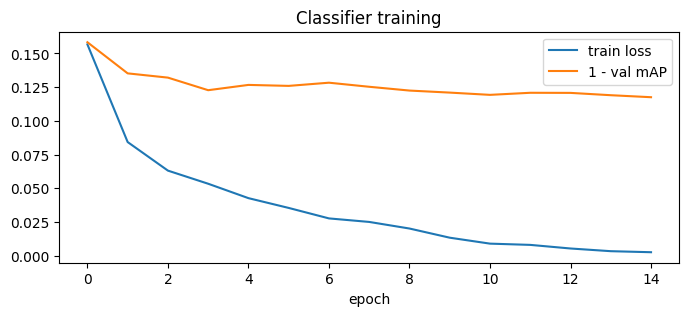

In [ ]:
cls_model, cls_hist, cls_map = fit_classifier(f'cls_{MODE}_{C.cls_arch}', C.cls_arch, CLS_TRAIN_IDS, VAL_IDS,
                                              C.cls_epochs, C.cls_bs, LR_CLS, C.cls_size)
record('classifier', dict(arch=C.cls_arch, val_mAP=cls_map, lr=LR_CLS, epochs=C.cls_epochs))
print(f'Image-level classification val mAP: {cls_map*100:.2f}')
plt.figure(figsize=(8, 3)); plt.plot([h['loss'] for h in cls_hist], label='train loss'); plt.plot([1 - h['val_map'] for h in cls_hist], label='1 - val mAP')
plt.legend(); plt.xlabel('epoch'); plt.title('Classifier training'); savefig('cls_training_curve'); plt.show()

## Stage 6 — CAM generation
* For each training image we only compute CAMs for the classes **present in its image-level label** (any other class is known to be absent).
* **Multi-scale + horizontal-flip** inference (`scales=(0.5,1,1.5,2)`): averages out scale/side bias -> more complete, less noisy maps (an ablation in Stage 11).
* Each class map is divided by its maximum -> values in [0,1].
* CAMs are cached on disk as float16 so that thresholds / refinement can be swept **without re-running the network**.

In [ ]:
@torch.no_grad()
def multi_scale_cam(model, img_u8, cls_idx, scales=(0.5, 1.0, 1.5, 2.0), flip=True):
    """-> (K,H,W) float32 in [0,1], K = len(cls_idx) (same order)"""
    model.eval(); H, W = img_u8.shape[:2]
    x = torch.from_numpy(normalize_np(img_u8))[None].to(device); acc = None
    for s in scales:
        xs = x if s == 1.0 else F.interpolate(x, scale_factor=s, mode='bilinear', align_corners=False)
        if flip: xs = torch.cat([xs, xs.flip(-1)], 0)
        with autocast(): m = model.cam_maps(xs)
        m = F.interpolate(m[:, cls_idx].float(), size=(H, W), mode='bilinear', align_corners=False)
        m = (m[0] + m[1].flip(-1)) if flip else m[0]
        acc = m if acc is None else acc + m
    acc = acc / (acc.flatten(1).max(1)[0].view(-1, 1, 1) + 1e-5)
    return acc.cpu().numpy()

def build_cam_cache(model, ids, cache_dir, scales=(0.5, 1.0, 1.5, 2.0), flip=True):
    cache_dir = Path(cache_dir); cache_dir.mkdir(parents=True, exist_ok=True)
    for i in tqdm(ids, desc=f'CAMs -> {cache_dir.name}'):
        f = cache_dir / f'{i}.npy'
        if f.exists(): continue
        img = np.array(load_image(i)); cls = LABELS[i]
        cam = multi_scale_cam(model, img, cls, scales, flip) if cls else np.zeros((0,) + img.shape[:2], np.float32)
        np.save(f, cam.astype(np.float16))

def load_cam(i, cache_dir): return np.load(Path(cache_dir) / f'{i}.npy').astype(np.float32)

CAM_DIR = LOCAL / f'cams_{MODE}_{C.cls_arch}_ms'
build_cam_cache(cls_model, TRAIN_IDS, CAM_DIR)

CAMs -> cams_LOW_GPU_resnet50_ms:   0%|          | 0/1464 [00:00<?, ?it/s]

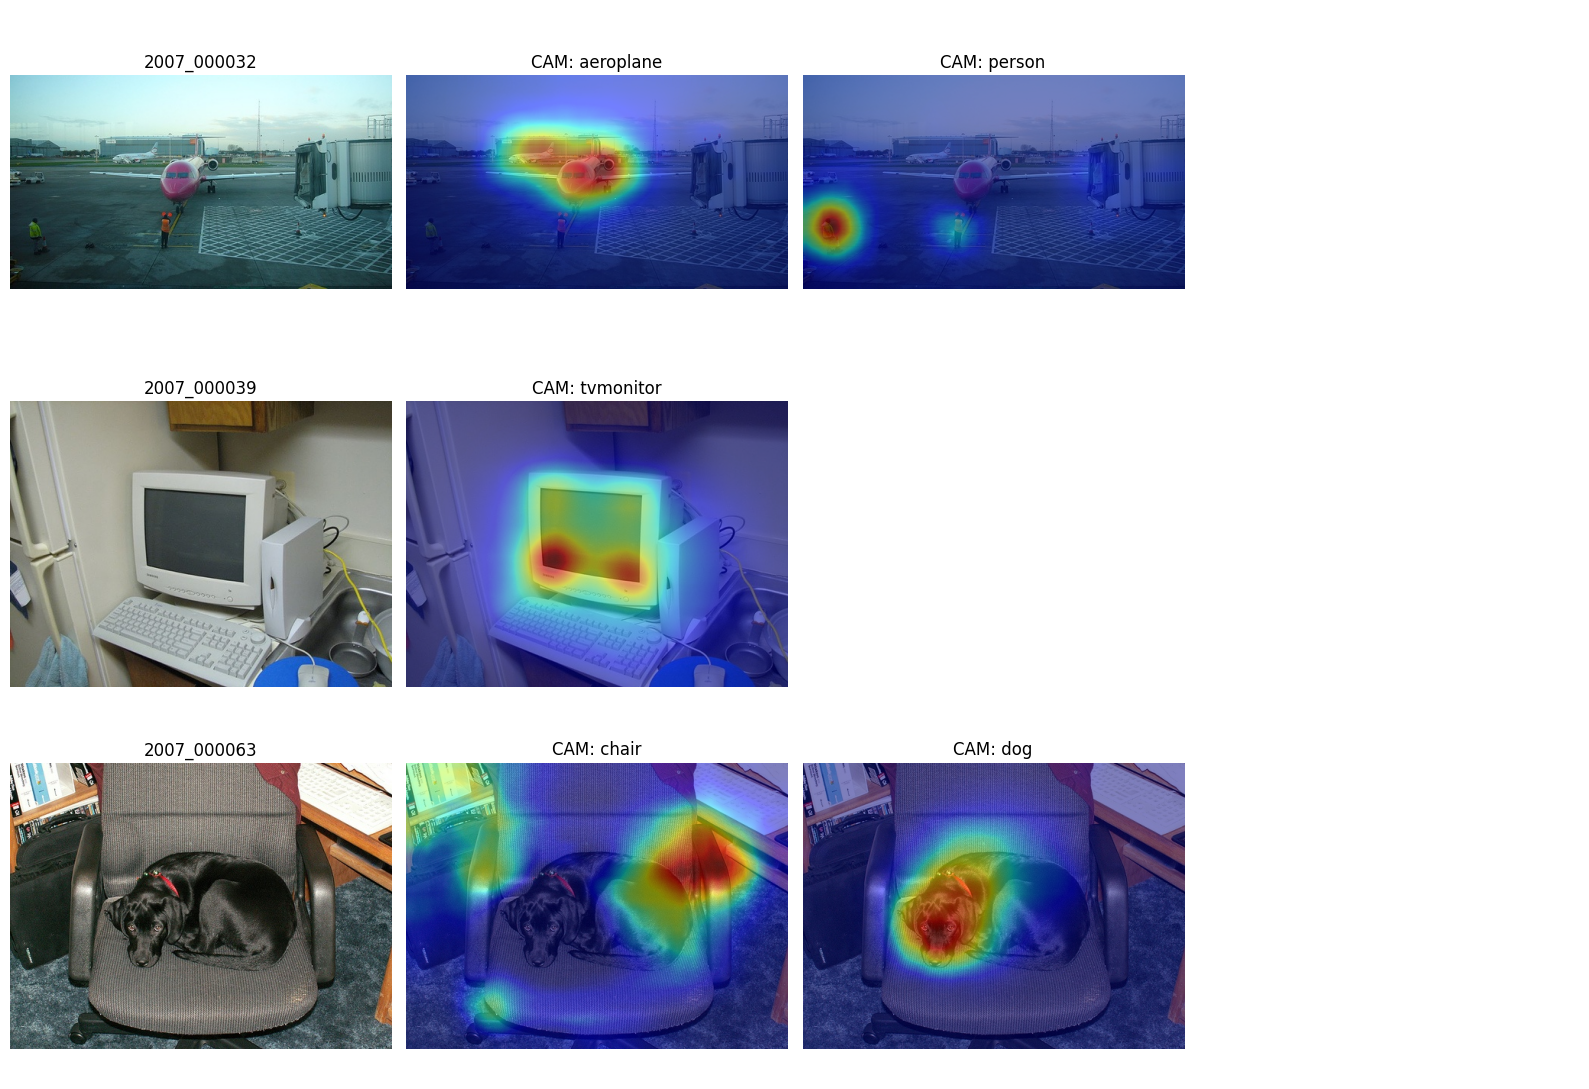

In [ ]:
# visual check: image | CAM heat-map per present class
fig, ax = plt.subplots(3, 4, figsize=(16, 11))
for r, i in enumerate(TRAIN_IDS[:3]):
    img = np.array(load_image(i)); cams = load_cam(i, CAM_DIR)
    ax[r, 0].imshow(img); ax[r, 0].set_title(i); ax[r, 0].axis('off')
    for k in range(3):
        a = ax[r, k + 1]; a.axis('off')
        if k < len(LABELS[i]):
            a.imshow(0.5 * img / 255 + 0.5 * plt.cm.jet(cams[k])[..., :3]); a.set_title('CAM: ' + CLASSES[LABELS[i][k]])
plt.tight_layout(); savefig('cam_examples'); plt.show()

## Stage 7 — Pseudo-masks and **refinement**

CAMs are **sparse** (they fire on the most discriminative part, e.g. a dog's head) and **blurry** (they ignore object boundaries). So:

1. **CAM -> mask:** for each pixel take the class with the highest CAM score; if that score is below threshold $\tau$ the pixel is **background**.
2. **Refinement** (three options, all compared in the ablation):
   * `none` — raw CAM (baseline).
   * `pamr` — **Pixel-Adaptive Mask Refinement** (Araslanov & Roth, CVPR'20, re-implemented here in pure PyTorch, no learnable weights): iteratively propagates the CAM scores between pixels with similar colour in a multi-dilation neighbourhood, so the mask snaps to real object boundaries and fills object interiors.
   * `crf` — fully-connected **DenseCRF** (works only if `pydensecrf` installs; optional).
3. **Dual-threshold ignore band (our design option):** pixels with score in $[\tau-\delta,\tau)$ are *uncertain* -> label `255` (ignored by the loss) instead of forcing a noisy label.

All hyper-parameters ($\tau$, PAMR iterations, $\delta$) are selected in 7.3.

In [ ]:
class PAMR(nn.Module):
    """Parameter-free affinity propagation guided by image colour. Input: normalised image (1,3,H,W), scores (1,K,H,W) in [0,1]."""
    def __init__(self, num_iter=10, dilations=(1, 2, 4, 8, 12, 24), sigma=0.1):
        super().__init__(); self.num_iter, self.dilations, self.sigma = num_iter, dilations, sigma
        self.offs = [(0, 0)] + [(dy * d, dx * d) for d in dilations for dy in (-1, 0, 1) for dx in (-1, 0, 1) if (dy, dx) != (0, 0)]
        self.pad = max(dilations)
    @staticmethod
    def _sh(xp, pad, H, W, dy, dx): return xp[:, :, pad + dy: pad + dy + H, pad + dx: pad + dx + W]
    @torch.no_grad()
    def forward(self, img, mask):
        img, mask = img.float(), mask.float(); _, _, H, W = img.shape; p = self.pad
        ip = F.pad(img, (p,) * 4, mode='replicate')
        D = torch.cat([(self._sh(ip, p, H, W, dy, dx) - img).abs().mean(1, keepdim=True) for dy, dx in self.offs], 1)   # (1,N,H,W)
        mu = F.avg_pool2d(img, 3, 1, 1); std = (F.avg_pool2d(img ** 2, 3, 1, 1) - mu ** 2).clamp_min(0).sqrt().mean(1, keepdim=True)
        A = torch.softmax(-D / (self.sigma * std + 1e-6), dim=1)                                                          # affinities
        for _ in range(self.num_iter):
            mp = F.pad(mask, (p,) * 4, mode='replicate'); out = 0
            for n, (dy, dx) in enumerate(self.offs): out = out + A[:, n:n + 1] * self._sh(mp, p, H, W, dy, dx)
            mask = out
        return mask

try:
    import pydensecrf.densecrf as dcrf
    from pydensecrf.utils import unary_from_softmax
    HAS_CRF = True
except Exception:
    HAS_CRF = False
print('DenseCRF available:', HAS_CRF, '(optional; install with: pip install git+https://github.com/lucasb-eyer/pydensecrf.git)')

def crf_refine(img_u8, probs, n_iter=10):
    C_, H, W = probs.shape; d = dcrf.DenseCRF2D(W, H, C_)
    d.setUnaryEnergy(np.ascontiguousarray(unary_from_softmax(probs)))
    d.addPairwiseGaussian(sxy=3, compat=3)
    d.addPairwiseBilateral(sxy=50, srgb=5, rgbim=np.ascontiguousarray(img_u8), compat=10)
    return np.array(d.inference(n_iter)).reshape(C_, H, W)

def scores_to_mask(cams, cls_idx, thr_hi, thr_lo=None):
    """cams (K,H,W) in [0,1] -> uint8 mask: 0 bg | 1..20 class | 255 ignore band [thr_lo, thr_hi)"""
    H, W = cams.shape[-2:]
    if cams.shape[0] == 0: return np.zeros((H, W), np.uint8)
    thr_lo = thr_hi if thr_lo is None else thr_lo
    mx, am = cams.max(0), cams.argmax(0)
    mask = (np.array(cls_idx)[am] + 1).astype(np.uint8)
    mask[mx < thr_hi] = 255; mask[mx < thr_lo] = 0
    return mask

def refine_scores(cams, img_u8, pamr):
    if cams.shape[0] == 0: return cams
    x = torch.from_numpy(normalize_np(img_u8))[None].to(device); m = torch.from_numpy(cams)[None].to(device)
    out = pamr(x, m)[0]; out = out / (out.flatten(1).max(1)[0].view(-1, 1, 1) + 1e-5)
    return out.cpu().numpy()

def crf_mask(i, cams, img_u8, thr):
    H, W = img_u8.shape[:2]
    probs = np.concatenate([np.full((1, H, W), thr, np.float32), cams], 0); probs = probs / probs.sum(0, keepdims=True)
    am = crf_refine(img_u8, probs).argmax(0); lut = np.array([0] + [c + 1 for c in LABELS[i]], np.uint8)
    return lut[am]

def make_mask(i, cam_dir, method, thr, delta=0.0, pamr=None, cams=None, img=None):
    img = np.array(load_image(i)) if img is None else img; cams = load_cam(i, cam_dir) if cams is None else cams
    if method == 'crf': return crf_mask(i, cams, img, thr)
    if method == 'pamr': cams = refine_scores(cams, img, pamr)
    return scores_to_mask(cams, LABELS[i], thr, max(thr - delta, 0.0))

DenseCRF available: False (optional; install with: pip install git+https://github.com/lucasb-eyer/pydensecrf.git)


### 7.1  Tools to *measure* pseudo-mask quality
Pseudo-mask mIoU vs GT on the train images (**diagnostic only** — it tells us how good the supervision for the segmentation network is). `ignore` = % of pixels left unlabeled by the ignore band.

In [ ]:
def sweep_pseudo(ids, cam_dir, method, thr_list, delta=0.0, pamr=None):
    """Refine ONCE per image, then evaluate every threshold -> {thr: dict(miou, ignore)}"""
    cms = {t: ConfusionMatrix(21) for t in thr_list}; ign = {t: [0, 0] for t in thr_list}
    for i in tqdm(ids, desc=f'sweep {method}', leave=False):
        img = np.array(load_image(i)); gt = load_gt(i); cams = load_cam(i, cam_dir)
        if method == 'pamr': cams = refine_scores(cams, img, pamr)
        for t in thr_list:
            m = crf_mask(i, cams, img, t) if method == 'crf' else scores_to_mask(cams, LABELS[i], t, max(t - delta, 0.0))
            cms[t].update(m, gt); ign[t][0] += int((m == 255).sum()); ign[t][1] += m.size
    return {t: dict(miou=cms[t].scores()['miou'], ignore=ign[t][0] / ign[t][1]) for t in thr_list}

def eval_mask_dir(ids, mask_dir):
    cm = ConfusionMatrix(21); ig = tot = 0
    for i in ids:
        m = np.array(Image.open(Path(mask_dir) / f'{i}.png')); cm.update(m, load_gt(i)); ig += (m == 255).sum(); tot += m.size
    s = cm.scores(); s['ignore'] = ig / tot; return s

def generate_pseudo_masks(ids, cam_dir, out_dir, method, thr, delta=0.0, pamr=None):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    for i in tqdm(ids, desc=f'pseudo-masks -> {out_dir.name}'):
        Image.fromarray(make_mask(i, cam_dir, method, thr, delta, pamr)).save(out_dir / f'{i}.png')

### 7.2  Hyper-parameter selection: threshold $\tau$ and PAMR iterations
Done on the first `n_hp_imgs` train images (cheap). **Disclosure for the paper:** this selection uses GT masks of a small train subset (common practice in WSSS, but state it).

sweep none:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

            none  pamr_5  pamr_10  pamr_20
threshold                                 
0.15       40.11   40.02    39.98    39.94
0.20       42.17   42.13    42.12    42.13
0.25       42.82   42.89    42.93    43.02
0.30       42.56   42.73    42.82    42.96
0.35       41.35   41.59    41.70    41.86
0.40       39.55   39.82    39.95    40.12
0.45       37.16   37.43    37.55    37.70
0.50       34.36   34.60    34.69    34.80
0.55       31.08   31.26    31.31    31.35
0.60       27.58   27.64    27.65    27.61


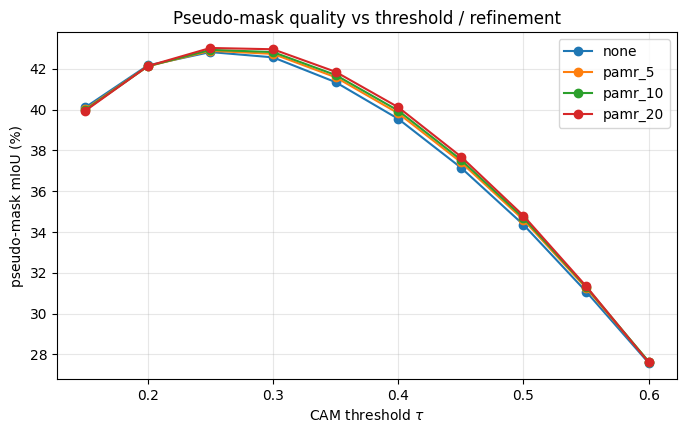

best raw CAM: tau=0.25 -> 42.82 | best PAMR: iters=20, tau=0.25 -> 43.02


In [ ]:
HP_IDS = TRAIN_IDS[:C.n_hp_imgs]
THRS = [0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
hp_res = {'none': sweep_pseudo(HP_IDS, CAM_DIR, 'none', THRS)}
for it_ in [5, 10, 20]:
    hp_res[f'pamr_{it_}'] = sweep_pseudo(HP_IDS, CAM_DIR, 'pamr', THRS, pamr=PAMR(it_).to(device))
if HAS_CRF: hp_res['crf'] = sweep_pseudo(HP_IDS, CAM_DIR, 'crf', THRS)

df_hp = pd.DataFrame({k: {t: v[t]['miou'] * 100 for t in THRS} for k, v in hp_res.items()}); df_hp.index.name = 'threshold'
print(df_hp.round(2)); df_hp.to_csv(TAB / 'hp_threshold_refinement.csv')
plt.figure(figsize=(8, 4.5))
for k in df_hp.columns: plt.plot(df_hp.index, df_hp[k], marker='o', label=k)
plt.xlabel('CAM threshold $\\tau$'); plt.ylabel('pseudo-mask mIoU (%)'); plt.grid(alpha=.3); plt.legend(); plt.title('Pseudo-mask quality vs threshold / refinement')
savefig('hp_threshold_sweep'); plt.show()

BEST_NONE_THR = float(df_hp['none'].idxmax())
pam_cols = [c for c in df_hp.columns if c.startswith('pamr')]
BEST_PAMR_COL = df_hp[pam_cols].max().idxmax(); PAMR_ITERS = int(BEST_PAMR_COL.split('_')[1]); BEST_PAMR_THR = float(df_hp[BEST_PAMR_COL].idxmax())
print(f'best raw CAM: tau={BEST_NONE_THR} -> {df_hp["none"].max():.2f} | best PAMR: iters={PAMR_ITERS}, tau={BEST_PAMR_THR} -> {df_hp[BEST_PAMR_COL].max():.2f}')
record('hp_selected', dict(thr_none=BEST_NONE_THR, thr_pamr=BEST_PAMR_THR, pamr_iters=PAMR_ITERS))
PAMR_MAIN = PAMR(PAMR_ITERS).to(device)

### 7.3  Generate the pseudo-masks for the whole training set (three variants) and measure their quality

In [ ]:
IGNORE_DELTA = 0.10
PSEUDO = {
    'cam_none':   dict(method='none', thr=BEST_NONE_THR, delta=0.0),
    'cam_pamr':   dict(method='pamr', thr=BEST_PAMR_THR, delta=0.0),            # MAIN configuration
    'cam_pamr_ig': dict(method='pamr', thr=BEST_PAMR_THR, delta=IGNORE_DELTA),  # + uncertain band ignored
}
PSEUDO_DIR, pq_rows = {}, []
for name, cfg in PSEUDO.items():
    PSEUDO_DIR[name] = LOCAL / f'pseudo_{MODE}' / name
    if len(list(PSEUDO_DIR[name].glob('*.png'))) < len(TRAIN_IDS):
        generate_pseudo_masks(TRAIN_IDS, CAM_DIR, PSEUDO_DIR[name], cfg['method'], cfg['thr'], cfg['delta'], PAMR_MAIN)
    s = eval_mask_dir(TRAIN_IDS, PSEUDO_DIR[name])
    pq_rows.append(dict(config=name, **cfg, pseudo_mIoU=s['miou'] * 100, pseudo_mDice=s['mdice'] * 100, ignore_pct=s['ignore'] * 100))
df_pq = pd.DataFrame(pq_rows); print(df_pq.round(2)); df_pq.to_csv(TAB / 'pseudo_mask_quality.csv', index=False)
record('pseudo_mask_quality', pq_rows)

pseudo-masks -> cam_none:   0%|          | 0/1464 [00:00<?, ?it/s]

pseudo-masks -> cam_pamr:   0%|          | 0/1464 [00:00<?, ?it/s]

pseudo-masks -> cam_pamr_ig:   0%|          | 0/1464 [00:00<?, ?it/s]

        config method   thr  delta  pseudo_mIoU  pseudo_mDice  ignore_pct
0     cam_none   none  0.25    0.0        44.17         60.39        0.00
1     cam_pamr   pamr  0.25    0.0        44.35         60.56        0.00
2  cam_pamr_ig   pamr  0.25    0.1        48.01         63.95       12.12


## Stage 8 — Train the WSSS segmentation network on the pseudo-masks
Exactly the **same architecture, schedule, and images** as the fully-supervised baseline; the *only* difference is the supervision (pseudo-masks from image-level labels). Evaluation is on real GT masks of the VOC val set.

In [ ]:
wsss_run = train_segmentation('wsss_cam_pamr', C.seg_arch, TRAIN_IDS, PSEUDO_DIR['cam_pamr'], C.seg_epochs, C.seg_bs, SEG_LR, C.seg_size,
                              accum=ACCUM, eval_every=C.eval_every)
ws = wsss_run['best']
record('wsss_main', dict(miou=ws['miou'], mdice=ws['mdice'], pixel_acc=ws['pixel_acc'], iou=ws['iou'], train_time_min=wsss_run['time'] / 60, epoch=ws['epoch']))
print(f"WSSS (CAM + PAMR)  mIoU {ws['miou']*100:.2f} | mDice {ws['mdice']*100:.2f} | pixAcc {ws['pixel_acc']*100:.2f}")
wsss_model = wsss_run['model']

wsss_cam_pamr ep 1/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_cam_pamr ep 2/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_cam_pamr ep 3/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_cam_pamr ep 4/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_cam_pamr ep 5/30:   0%|          | 0/183 [00:00<?, ?it/s]

...

wsss_cam_pamr ep 28/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_cam_pamr ep 29/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_cam_pamr ep 30/30:   0%|          | 0/183 [00:00<?, ?it/s]

eval:   0%|          | 0/1449 [00:00<?, ?it/s]

[wsss_cam_pamr] ep 30: loss 0.3851 | val mIoU 38.40 | pixAcc 76.97 | 27.7 min
WSSS (CAM + PAMR)  mIoU 38.40 | mDice 54.12 | pixAcc 76.97


## Stage 9 — Our extension: self-training (round 2)
**Idea.** The WSSS network has *seen thousands of images*, so its predictions are often cleaner than the CAM pseudo-masks it was trained on (it generalises across images, CAMs are per-image). So:
1. Predict each train image with the round-1 network (flip-averaged),
2. **restrict the prediction to classes in the image-level label** (+ background) — this is where weak supervision is still used,
3. keep only pixels with confidence $\ge 0.7$, mark the rest `255`,
4. retrain a fresh network on these new masks.

This is **our own addition** on top of the reference pipeline (state it clearly in the paper's "own work vs reused" table).

In [ ]:
@torch.no_grad()
def predict_probs(model, img_u8, flip=True, allowed=None):
    model.eval(); x = torch.from_numpy(normalize_np(img_u8))[None].to(device)
    with autocast():
        o = model(x)['out'].float()
        if flip: o = (o + model(x.flip(-1))['out'].float().flip(-1)) / 2
    if allowed is not None:
        keep = torch.full((21,), float('-inf'), device=device); keep[allowed] = 0; o = o + keep.view(1, -1, 1, 1)
    return F.softmax(o, 1)[0].cpu().numpy()

def self_training_masks(model, ids, out_dir, conf_thr=0.7):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    for i in tqdm(ids, desc='round-2 pseudo-masks'):
        p = predict_probs(model, np.array(load_image(i)), True, [0] + [c + 1 for c in LABELS[i]])
        m = p.argmax(0).astype(np.uint8); m[p.max(0) < conf_thr] = 255
        Image.fromarray(m).save(out_dir / f'{i}.png')

R2_CONF = 0.7
PSEUDO_DIR['round2'] = LOCAL / f'pseudo_{MODE}' / 'round2'
if len(list(PSEUDO_DIR['round2'].glob('*.png'))) < len(TRAIN_IDS):
    self_training_masks(wsss_model, TRAIN_IDS, PSEUDO_DIR['round2'], R2_CONF)
s = eval_mask_dir(TRAIN_IDS, PSEUDO_DIR['round2'])
print(f"round-2 pseudo-mask quality: mIoU {s['miou']*100:.2f} (ignore {s['ignore']*100:.1f}%)  vs round-1 {df_pq.loc[df_pq.config=='cam_pamr','pseudo_mIoU'].values[0]:.2f}")
record('pseudo_round2', dict(miou=s['miou'], ignore=s['ignore']))
del wsss_run; clear_gpu()

r2_run = train_segmentation('wsss_round2', C.seg_arch, TRAIN_IDS, PSEUDO_DIR['round2'], C.seg_epochs, C.seg_bs, SEG_LR, C.seg_size,
                            accum=ACCUM, eval_every=C.eval_every)
r2 = r2_run['best']
record('wsss_round2', dict(miou=r2['miou'], mdice=r2['mdice'], pixel_acc=r2['pixel_acc'], iou=r2['iou'], train_time_min=r2_run['time'] / 60))
print(f"WSSS round-2 (self-training)  mIoU {r2['miou']*100:.2f}")
del r2_run; clear_gpu()

round-2 pseudo-masks:   0%|          | 0/1464 [00:00<?, ?it/s]

round-2 pseudo-mask quality: mIoU 48.58 (ignore 10.2%)  vs round-1 44.35


wsss_round2 ep 1/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_round2 ep 2/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_round2 ep 3/30:   0%|          | 0/183 [00:00<?, ?it/s]

...

wsss_round2 ep 28/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_round2 ep 29/30:   0%|          | 0/183 [00:00<?, ?it/s]

wsss_round2 ep 30/30:   0%|          | 0/183 [00:00<?, ?it/s]

eval:   0%|          | 0/1449 [00:00<?, ?it/s]

[wsss_round2] ep 30: loss 0.2340 | val mIoU 36.85 | pixAcc 74.41 | 27.8 min
WSSS round-2 (self-training)  mIoU 36.85


## Stage 10 — WSSS vs fully-supervised: the accuracy gap (required deliverable)

                                 Method Supervision  mIoU  mDice  PixAcc  % of full-sup mIoU  Gap (mIoU pts)
         Fully supervised (pixel masks) Pixel-level 59.29  72.87   89.68              100.00            0.00
                       WSSS: CAM + PAMR Image-level 38.40  54.12   76.97               64.77           20.89
WSSS: CAM + PAMR + self-training (ours) Image-level 36.85  52.47   74.41               62.15           22.44


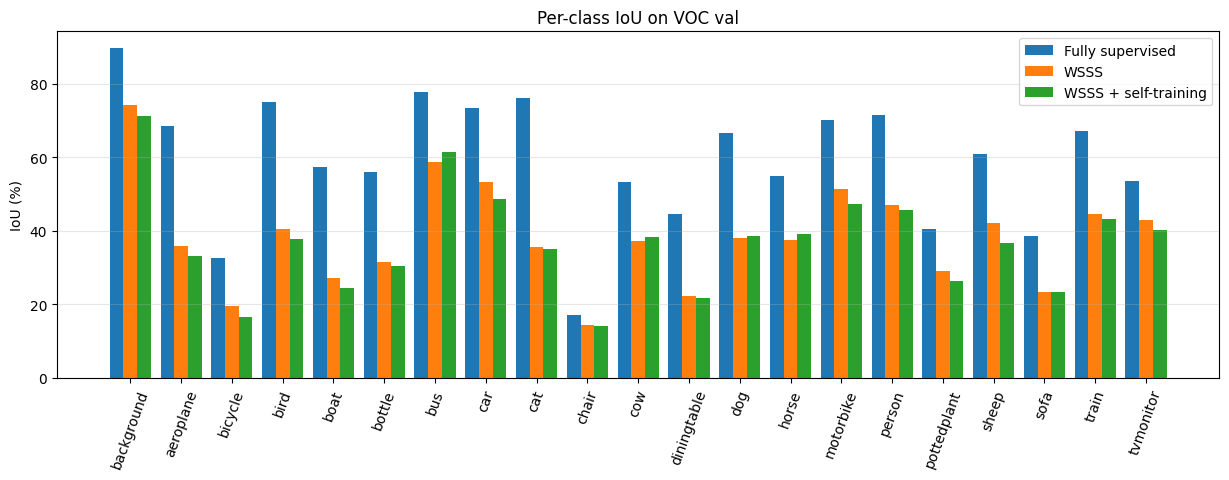

Largest gaps: cat (-40.6), bird (-34.6), aeroplane (-32.5), boat (-30.2), dog (-28.7)


In [ ]:
fs, w1, w2 = RESULTS['fully_supervised'], RESULTS['wsss_main'], RESULTS['wsss_round2']
rows = [('Fully supervised (pixel masks)', 'Pixel-level', fs), ('WSSS: CAM + PAMR', 'Image-level', w1), ('WSSS: CAM + PAMR + self-training (ours)', 'Image-level', w2)]
df_main = pd.DataFrame([dict(Method=n, Supervision=sv, mIoU=r['miou'] * 100, mDice=r['mdice'] * 100, PixAcc=r['pixel_acc'] * 100,
                             **{'% of full-sup mIoU': r['miou'] / fs['miou'] * 100, 'Gap (mIoU pts)': (fs['miou'] - r['miou']) * 100}) for n, sv, r in rows])
print(df_main.round(2).to_string(index=False)); df_main.to_csv(TAB / 'main_results.csv', index=False)

dfc = pd.DataFrame({'class': VOC_NAMES, 'FullSup': np.array(fs['iou']) * 100, 'WSSS': np.array(w1['iou']) * 100, 'WSSS+ST': np.array(w2['iou']) * 100})
dfc['gap'] = dfc['FullSup'] - dfc['WSSS']; dfc.to_csv(TAB / 'per_class_iou.csv', index=False)
x = np.arange(21); plt.figure(figsize=(15, 4.5)); wdt = .27
plt.bar(x - wdt, dfc.FullSup, wdt, label='Fully supervised'); plt.bar(x, dfc.WSSS, wdt, label='WSSS'); plt.bar(x + wdt, dfc['WSSS+ST'], wdt, label='WSSS + self-training')
plt.xticks(x, VOC_NAMES, rotation=70); plt.ylabel('IoU (%)'); plt.legend(); plt.grid(axis='y', alpha=.3); plt.title('Per-class IoU on VOC val')
savefig('per_class_iou'); plt.show()
print('Largest gaps:', ', '.join(f'{r["class"]} (-{r.gap:.1f})' for _, r in dfc.sort_values('gap', ascending=False).head(5).iterrows()))

## Stage 11 — Ablation studies (required: >= 2 design choices removed/changed, rest fixed)

| | What changes | Cost |
|---|---|---|
| **11A** | CAM inference: single-scale / +flip / multi-scale+flip; refinement: none / PAMR (iters, sigma) / CRF; ignore-band width $\delta$ | cheap (pseudo-mask mIoU on `n_abl_imgs`) |
| **11B** | Classifier backbone: ResNet-18 vs ResNet-50 | cheap-medium |
| **11C** | **End-to-end:** train segmentation with no refinement / PAMR / PAMR + ignore band / + self-training and evaluate on VOC val | expensive (one training per row) |

For each CAM variant we re-pick the best threshold, so no variant is handicapped by a bad $\tau$.

In [ ]:
# ------------------- 11A: CAM / refinement / ignore-band ablations (pseudo-mask quality) -------------------
ABL_IDS = TRAIN_IDS[:C.n_abl_imgs]
def best_of(r): t = max(r, key=lambda t: r[t]['miou']); return t, r[t]['miou'] * 100

camvars = [('Single-scale', 'ss', (1.0,), False), ('Single-scale + flip', 'ss_flip', (1.0,), True), ('Multi-scale + flip (ours)', 'ms', (0.5, 1.0, 1.5, 2.0), True)]
rows_a1 = []
for disp, key, sc, fl in camvars:
    d = CAM_DIR if key == 'ms' else LOCAL / f'cams_abl_{MODE}' / key
    if key != 'ms': build_cam_cache(cls_model, ABL_IDS, d, sc, fl)
    tn, mn = best_of(sweep_pseudo(ABL_IDS, d, 'none', THRS)); tp, mp = best_of(sweep_pseudo(ABL_IDS, d, 'pamr', THRS, pamr=PAMR_MAIN))
    rows_a1.append({'CAM inference': disp, 'raw CAM mIoU': mn, 'best tau (raw)': tn, 'CAM+PAMR mIoU': mp, 'best tau (PAMR)': tp})
df_a1 = pd.DataFrame(rows_a1); print('\n[A1] CAM inference ablation'); print(df_a1.round(2).to_string(index=False)); df_a1.to_csv(TAB / 'abl_cam_inference.csv', index=False)

rows_a2 = [{'Refinement': 'None (raw CAM)', 'mIoU': best_of(sweep_pseudo(ABL_IDS, CAM_DIR, 'none', THRS))[1]}]
for it_ in [5, 10, 20, 40]:
    rows_a2.append({'Refinement': f'PAMR, {it_} iterations', 'mIoU': best_of(sweep_pseudo(ABL_IDS, CAM_DIR, 'pamr', THRS, pamr=PAMR(it_).to(device)))[1]})
for sg in [0.05, 0.2]:
    rows_a2.append({'Refinement': f'PAMR, {PAMR_ITERS} it., sigma={sg}', 'mIoU': best_of(sweep_pseudo(ABL_IDS, CAM_DIR, 'pamr', THRS, pamr=PAMR(PAMR_ITERS, sigma=sg).to(device)))[1]})
if HAS_CRF: rows_a2.append({'Refinement': 'DenseCRF', 'mIoU': best_of(sweep_pseudo(ABL_IDS, CAM_DIR, 'crf', THRS))[1]})
df_a2 = pd.DataFrame(rows_a2); print('\n[A2] Refinement ablation'); print(df_a2.round(2).to_string(index=False)); df_a2.to_csv(TAB / 'abl_refinement.csv', index=False)

rows_a3 = []
for dl_ in [0.0, 0.05, 0.10, 0.15, 0.20]:
    r = sweep_pseudo(ABL_IDS, CAM_DIR, 'pamr', [BEST_PAMR_THR], delta=dl_, pamr=PAMR_MAIN)[BEST_PAMR_THR]
    rows_a3.append({'ignore band delta': dl_, 'mIoU on labelled px': r['miou'] * 100, 'ignored px (%)': r['ignore'] * 100})
df_a3 = pd.DataFrame(rows_a3); print('\n[A3] Ignore-band ablation (note: mIoU is on labelled pixels only; coverage drops)'); print(df_a3.round(2).to_string(index=False)); df_a3.to_csv(TAB / 'abl_ignore_band.csv', index=False)
record('abl_cam_inference', rows_a1); record('abl_refinement', rows_a2); record('abl_ignore_band', rows_a3)

CAMs -> ss:   0%|          | 0/300 [00:00<?, ?it/s]

sweep none:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

CAMs -> ss_flip:   0%|          | 0/300 [00:00<?, ?it/s]

sweep none:   0%|          | 0/300 [00:00<?, ?it/s]

...

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]


[A3] Ignore-band ablation (note: mIoU is on labelled pixels only; coverage drops)
 ignore band delta  mIoU on labelled px  ignored px (%)
              0.00                43.02            0.00
              0.05                44.63            5.67
              0.10                46.14           12.51
              0.15                47.61           21.25
              0.20                49.09           33.50


In [ ]:
# ------------------- 11B: classifier backbone (ResNet-18 vs ResNet-50) -------------------
rows_b = []
for arch in ['resnet18', C.cls_arch]:
    if arch == C.cls_arch: m, mp_cls, d = cls_model, cls_map, CAM_DIR
    else:
        m, _, mp_cls = fit_classifier(f'cls_{MODE}_{arch}', arch, CLS_TRAIN_IDS, VAL_IDS, C.cls_epochs, C.cls_bs, LR_CLS, C.cls_size)
        d = LOCAL / f'cams_abl_{MODE}' / f'{arch}_ms'; build_cam_cache(m, ABL_IDS, d)
    tn, mn = best_of(sweep_pseudo(ABL_IDS, d, 'none', THRS)); tp, mp = best_of(sweep_pseudo(ABL_IDS, d, 'pamr', THRS, pamr=PAMR_MAIN))
    rows_b.append({'Backbone': arch, 'cls val mAP': mp_cls * 100, 'params (M)': sum(p.numel() for p in m.parameters()) / 1e6, 'raw CAM mIoU': mn, 'CAM+PAMR mIoU': mp})
    if arch != C.cls_arch: del m; clear_gpu()
df_b = pd.DataFrame(rows_b); print(df_b.round(2).to_string(index=False)); df_b.to_csv(TAB / 'abl_backbone.csv', index=False); record('abl_backbone', rows_b)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


cls_LOW_GPU_resnet18 ep 1/15:   0%|          | 0/91 [00:00<?, ?it/s]

[cls_LOW_GPU_resnet18] ep 1: loss 0.1844 | val mAP 76.03


cls_LOW_GPU_resnet18 ep 2/15:   0%|          | 0/91 [00:00<?, ?it/s]

...

sweep none:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

sweep none:   0%|          | 0/300 [00:00<?, ?it/s]

sweep pamr:   0%|          | 0/300 [00:00<?, ?it/s]

Backbone  cls val mAP  params (M)  raw CAM mIoU  CAM+PAMR mIoU
resnet18        83.55       11.19         41.43          41.72
resnet50        88.25       23.55         42.82          43.02


In [ ]:
# ------------------- 11C: END-TO-END ablation (train segmentation for each pseudo-label variant) -------------------
E2E_NAMES = {'cam_none': 'CAM only (no refinement)', 'cam_pamr': 'CAM + PAMR', 'cam_pamr_ig': 'CAM + PAMR + ignore band'}
rows_c = []
for name, disp in E2E_NAMES.items():
    if name == 'cam_pamr' and C.abl_epochs == C.seg_epochs: sc = RESULTS['wsss_main']
    elif not RUN_ABL_SEG_TRAINING: print('skipping', name); continue
    else:
        run = train_segmentation(f'abl_{MODE}_{name}', C.seg_arch, TRAIN_IDS, PSEUDO_DIR[name], C.abl_epochs, C.seg_bs, SEG_LR, C.seg_size,
                                 accum=ACCUM, eval_every=C.eval_every)
        sc = run['best']; del run; clear_gpu()
    pq = df_pq.loc[df_pq.config == name].iloc[0]
    rows_c.append({'Pseudo-label variant': disp, 'pseudo-mask mIoU (train)': pq.pseudo_mIoU, 'ignored px (%)': pq.ignore_pct, 'final val mIoU': sc['miou'] * 100})
rows_c.append({'Pseudo-label variant': 'CAM + PAMR + self-training (ours)', 'pseudo-mask mIoU (train)': RESULTS['pseudo_round2']['miou'] * 100,
               'ignored px (%)': RESULTS['pseudo_round2']['ignore'] * 100, 'final val mIoU': RESULTS['wsss_round2']['miou'] * 100})
rows_c.append({'Pseudo-label variant': 'Fully supervised (reference)', 'pseudo-mask mIoU (train)': 100.0, 'ignored px (%)': 0.0, 'final val mIoU': RESULTS['fully_supervised']['miou'] * 100})
df_c = pd.DataFrame(rows_c); print(df_c.round(2).to_string(index=False)); df_c.to_csv(TAB / 'abl_end_to_end.csv', index=False); record('abl_end_to_end', rows_c)

abl_LOW_GPU_cam_none ep 1/30:   0%|          | 0/183 [00:00<?, ?it/s]

abl_LOW_GPU_cam_none ep 2/30:   0%|          | 0/183 [00:00<?, ?it/s]

abl_LOW_GPU_cam_none ep 3/30:   0%|          | 0/183 [00:00<?, ?it/s]

abl_LOW_GPU_cam_none ep 4/30:   0%|          | 0/183 [00:00<?, ?it/s]

abl_LOW_GPU_cam_none ep 5/30:   0%|          | 0/183 [00:00<?, ?it/s]

...

abl_LOW_GPU_cam_pamr_ig ep 28/30:   0%|          | 0/183 [00:00<?, ?it/s]

abl_LOW_GPU_cam_pamr_ig ep 29/30:   0%|          | 0/183 [00:00<?, ?it/s]

abl_LOW_GPU_cam_pamr_ig ep 30/30:   0%|          | 0/183 [00:00<?, ?it/s]

eval:   0%|          | 0/1449 [00:00<?, ?it/s]

[abl_LOW_GPU_cam_pamr_ig] ep 30: loss 0.3186 | val mIoU 37.80 | pixAcc 74.42 | 27.3 min
             Pseudo-label variant  pseudo-mask mIoU (train)  ignored px (%)  final val mIoU
         CAM only (no refinement)                     44.17            0.00           38.40
                       CAM + PAMR                     44.35            0.00           38.40
         CAM + PAMR + ignore band                     48.01           12.12           37.80
CAM + PAMR + self-training (ours)                     48.58           10.16           36.85
     Fully supervised (reference)                    100.00            0.00           59.29


## Stage 12 — Visualisation & error analysis
1. The **whole pipeline** on one image: image -> GT -> CAM -> raw pseudo-mask -> refined pseudo-mask -> FS prediction -> WSSS prediction.
2. Training curves. 3. Failure cases (worst WSSS images).

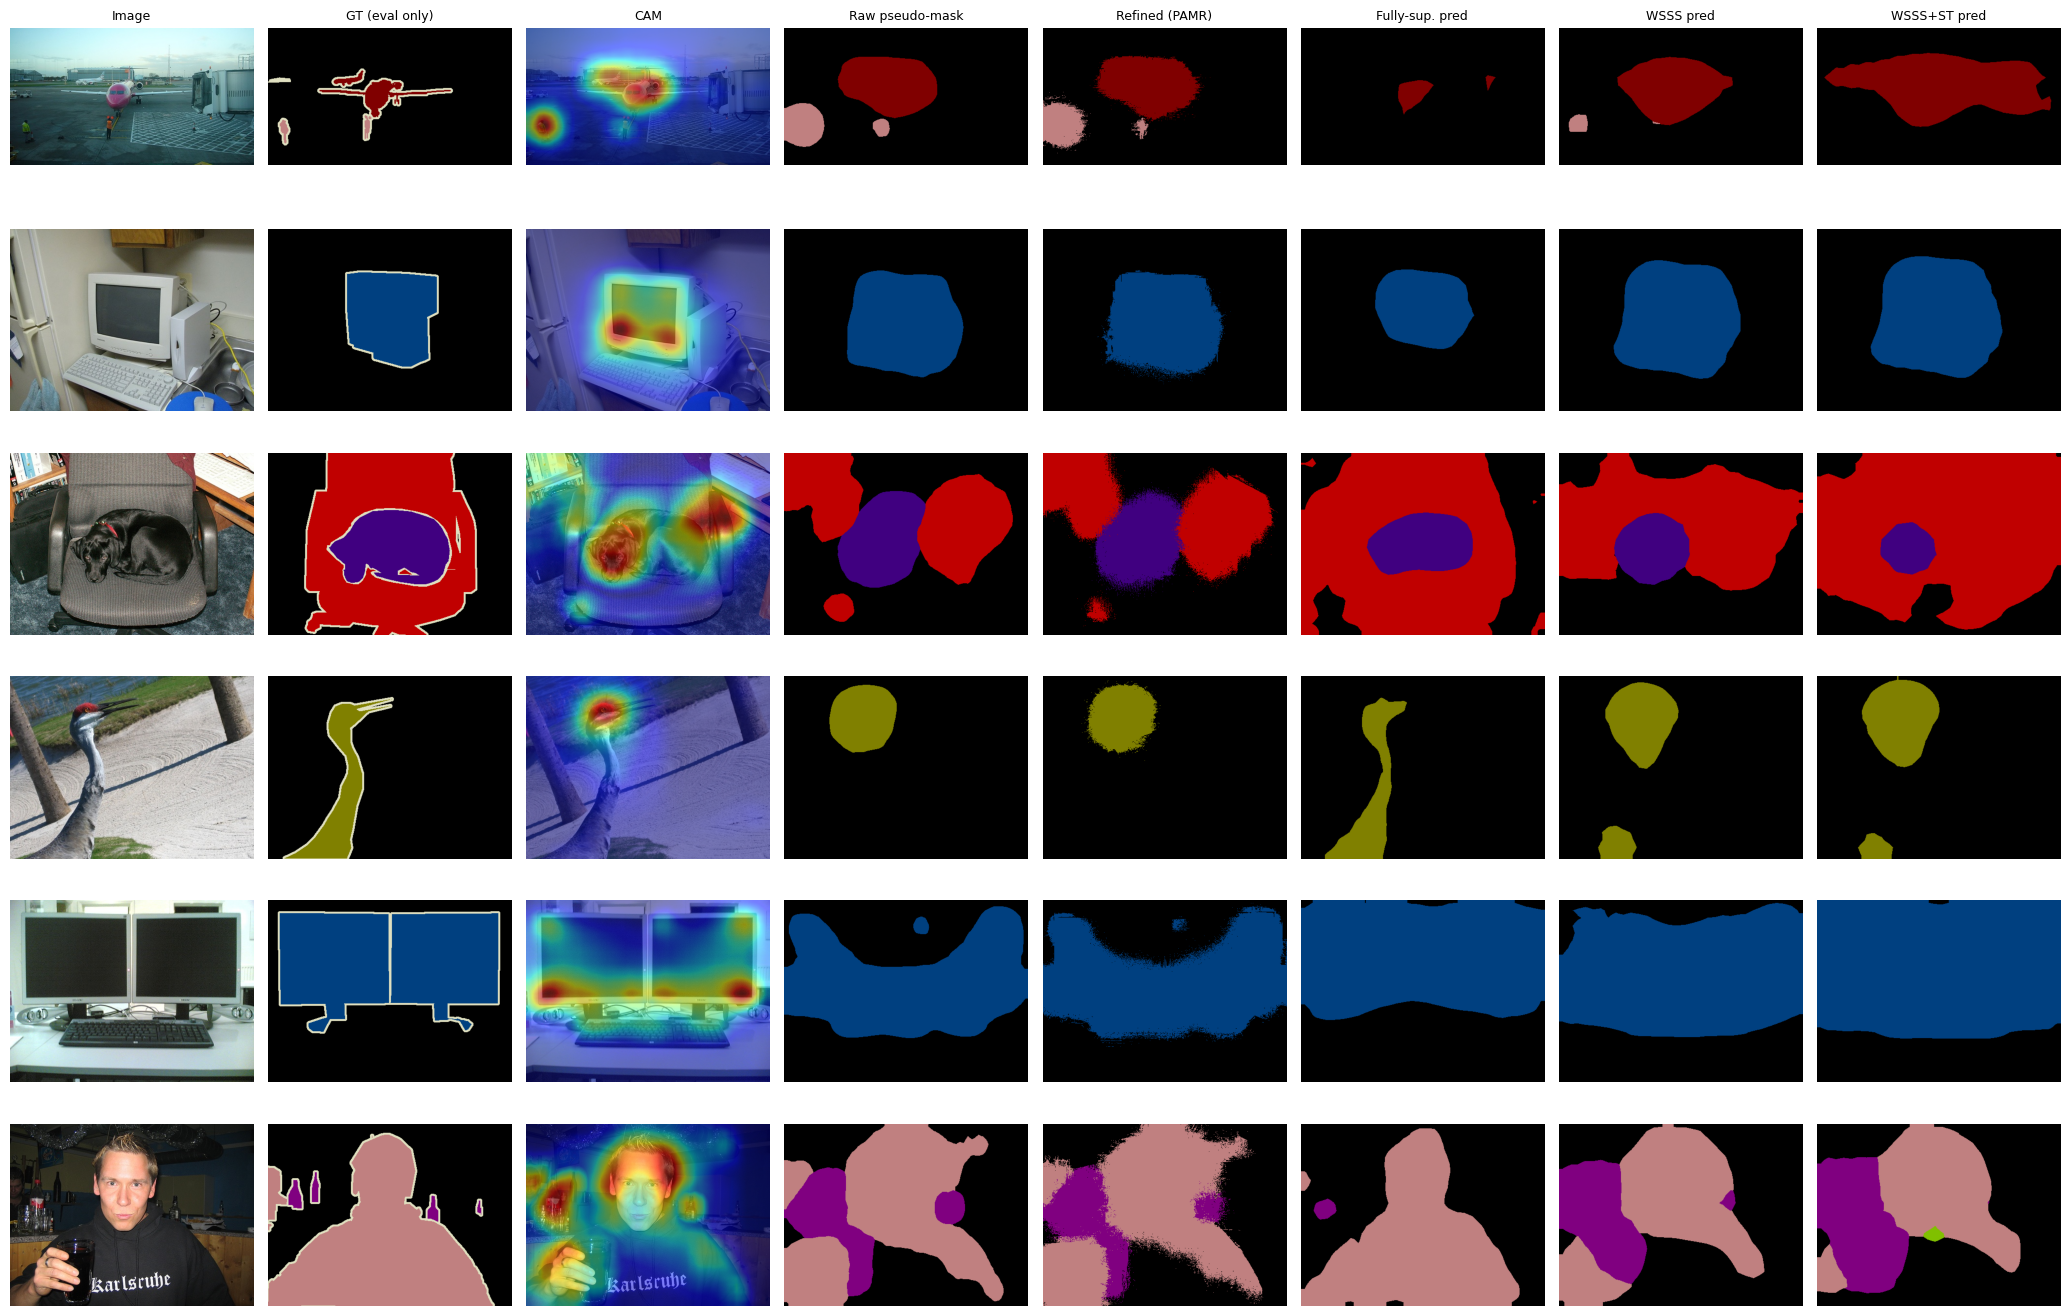

In [ ]:
def load_seg(tag, arch):
    m = build_seg_model(arch, pretrained=False).to(device)
    m.load_state_dict(torch.load(CKPT / f'{tag}_best.pth', map_location=device)); return m.eval()
fs_model  = load_seg('fully_sup', C.seg_arch)
r2_model  = load_seg('wsss_round2', C.seg_arch)

def argmax_pred(model, img): return predict_probs(model, img, True).argmax(0).astype(np.uint8)

def show_pipeline(ids, fname):
    cols = ['Image', 'GT (eval only)', 'CAM', 'Raw pseudo-mask', 'Refined (PAMR)', 'Fully-sup. pred', 'WSSS pred', 'WSSS+ST pred']
    fig, ax = plt.subplots(len(ids), len(cols), figsize=(2.6 * len(cols), 2.3 * len(ids)))
    ax = np.atleast_2d(ax)
    for r, i in enumerate(ids):
        img = np.array(load_image(i)); cams = load_cam(i, CAM_DIR) if i in TRAIN_IDS else None
        gt = load_gt(i)
        panels = [img, colorize(gt)]
        if cams is not None:
            panels += [0.5 * img / 255 + 0.5 * plt.cm.jet(cams.max(0))[..., :3],
                       colorize(make_mask(i, CAM_DIR, 'none', BEST_NONE_THR, cams=cams, img=img)),
                       colorize(make_mask(i, CAM_DIR, 'pamr', BEST_PAMR_THR, pamr=PAMR_MAIN, cams=cams, img=img))]
        else: panels += [np.zeros_like(img)] * 3
        panels += [colorize(argmax_pred(fs_model, img)), colorize(argmax_pred(wsss_model, img)), colorize(argmax_pred(r2_model, img))]
        for c, p in enumerate(panels):
            ax[r, c].imshow(p); ax[r, c].axis('off')
            if r == 0: ax[r, c].set_title(cols[c], fontsize=9)
    plt.tight_layout(); savefig(fname); plt.show()
show_pipeline(TRAIN_IDS[:6], 'pipeline_train_examples')

In [ ]:
# ---- training curves ----
def load_hist(tag): p = LOG / f'{tag}_history.json'; return json.load(open(p)) if p.exists() else []
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for tag, lab in [('fully_sup', 'Fully supervised'), ('wsss_cam_pamr', 'WSSS (CAM+PAMR)'), ('wsss_round2', 'WSSS + self-training')]:
    h = load_hist(tag)
    if not h: continue
    ax[0].plot([r['epoch'] for r in h], [r['loss'] for r in h], label=lab)
    v = [(r['epoch'], r['val_miou'] * 100) for r in h if 'val_miou' in r]; ax[1].plot(*zip(*v), marker='o', label=lab)
ax[0].set_title('Training loss'); ax[1].set_title('Val mIoU (%)'); ax[0].set_xlabel('epoch'); ax[1].set_xlabel('epoch'); ax[0].legend(); ax[1].legend(); ax[1].grid(alpha=.3)
savefig('training_curves'); plt.show()

# ---- failure cases: worst WSSS val images ----
sc_img = []
for i in tqdm(VAL_IDS[:300], desc='per-image IoU'):
    img = np.array(load_image(i)); cm_ = ConfusionMatrix(21); cm_.update(argmax_pred(wsss_model, img), load_gt(i)); sc_img.append((cm_.scores()['miou'], i))
worst = [i for _, i in sorted(sc_img)[:5]]
show_pipeline(worst, 'failure_cases'); print('worst val images:', worst)
print('Classes present in the worst images:', [[CLASSES[c] for c in LABELS[i]] for i in worst])

## Stage 13 — Comparison with published results & efficiency

> **Verify every literature number against the original paper before putting it in your report** (these are the numbers as commonly reported on VOC val/test with image-level supervision; different backbones / extra data / saliency usage make comparisons only approximate). Fill the **SemPLeS** row from the reference paper given in your problem statement.
>
> Our numbers will be **lower** than published ones because of the **low-GPU budget** (MobileNetV3 segmenter, 320 px, 1,464 train images instead of the 10,582 `train_aug` set, no CRF post-processing at test time). Say so explicitly — that is an honest limitation, not a failure.

In [ ]:
lit = pd.DataFrame([
    dict(Method='AffinityNet / PSA (CVPR 2018)', Backbone='ResNet-38', Supervision='Image', val=61.7, test=63.7),
    dict(Method='IRN (CVPR 2019)',               Backbone='ResNet-50', Supervision='Image', val=63.5, test=64.8),
    dict(Method='SEAM (CVPR 2020)',              Backbone='ResNet-38', Supervision='Image', val=64.5, test=65.7),
    dict(Method='SemPLeS (reference paper) -> FILL FROM PAPER', Backbone='see paper', Supervision='Image (+text prompts)', val=np.nan, test=np.nan),
])
ours = pd.DataFrame([
    dict(Method='Ours: fully supervised',          Backbone=f'DeepLabV3-{C.seg_arch}', Supervision='Pixel',  val=fs['miou'] * 100, test=np.nan),
    dict(Method='Ours: CAM + PAMR',                Backbone=f'DeepLabV3-{C.seg_arch}', Supervision='Image',  val=w1['miou'] * 100, test=np.nan),
    dict(Method='Ours: CAM + PAMR + self-training', Backbone=f'DeepLabV3-{C.seg_arch}', Supervision='Image',  val=w2['miou'] * 100, test=np.nan),
])
df_sota = pd.concat([lit, ours], ignore_index=True); print(df_sota.round(1).to_string(index=False)); df_sota.to_csv(TAB / 'sota_comparison.csv', index=False)

# ---- efficiency ----
def n_params(m): return sum(p.numel() for p in m.parameters()) / 1e6
def speed(model, ids, n=20):
    imgs = [np.array(load_image(i)) for i in ids[:n]]; predict_probs(model, imgs[0], False)
    if device.type == 'cuda': torch.cuda.synchronize()
    t = time.time()
    for im in imgs: predict_probs(model, im, False)
    if device.type == 'cuda': torch.cuda.synchronize()
    return len(imgs) / (time.time() - t)
df_eff = pd.DataFrame([
    dict(Model='Segmenter (' + C.seg_arch + ')', Params_M=n_params(fs_model), Inference_img_per_s=speed(fs_model, VAL_IDS),
         FullSup_train_min=RESULTS['fully_supervised']['train_time_min'], WSSS_train_min=RESULTS['wsss_main']['train_time_min']),
    dict(Model='CAM classifier (' + C.cls_arch + ')', Params_M=n_params(cls_model), Inference_img_per_s=np.nan, FullSup_train_min=np.nan,
         WSSS_train_min=cls_hist[-1]['time'] / 60)])
print(df_eff.round(2).to_string(index=False)); df_eff.to_csv(TAB / 'efficiency.csv', index=False)

## Stage 14 — Export everything for the IEEE paper
Generates the LaTeX tables, collects figures, and zips the `results/` folder.

In [ ]:
def to_latex(df, name, caption, label, fmt='%.1f'):
    try: tex = df.to_latex(index=False, float_format=fmt, na_rep='--', caption=caption, label=label)
    except Exception as e: tex = df.to_string(index=False); print('latex export fallback:', e)
    (TAB / f'{name}.tex').write_text(tex); return tex

to_latex(df_main, 'table_main', 'Weakly- vs fully-supervised segmentation on VOC 2012 val.', 'tab:main')
to_latex(df_c, 'table_ablation_e2e', 'End-to-end ablation of the pseudo-label pipeline (VOC 2012 val mIoU).', 'tab:abl_e2e')
to_latex(df_a1, 'table_ablation_cam', 'Ablation of CAM inference (pseudo-mask mIoU on train subset).', 'tab:abl_cam')
to_latex(df_a2, 'table_ablation_refine', 'Ablation of the refinement stage (pseudo-mask mIoU on train subset).', 'tab:abl_ref')
to_latex(df_b, 'table_ablation_backbone', 'Effect of the classifier backbone on CAM quality.', 'tab:abl_bb')
to_latex(df_sota, 'table_sota', 'Comparison with published image-level-supervised methods.', 'tab:sota')

record('config', dict(MODE=MODE, **vars(C), accum=ACCUM, seg_lr=SEG_LR, cls_lr=LR_CLS, seed=SEED))
print('Saved to', RES); print(sorted(p.name for p in TAB.iterdir())); print(sorted(p.name for p in FIG.iterdir()))
shutil.make_archive(str(PROJECT_ROOT / f'wsss_results_{MODE}'), 'zip', RES)
print('Zipped ->', PROJECT_ROOT / f'wsss_results_{MODE}.zip')
print('\n===== HEADLINE =====')
print(df_main.round(2).to_string(index=False))

## Stage 15 — Turning this into the IEEE paper, the PPT and the viva

### Paper (IEEE two-column) — map notebook outputs to sections
| Section | Take from |
|---|---|
| Abstract / Introduction | motivation (annotation cost), your headline table (`table_main`) |
| Related work | CAM (Zhou'16), AffinityNet/PSA, IRN, SEAM, PAMR, **SemPLeS** (reference), DeepLabV3 |
| Problem formulation | Stage 1-2 (VOC, image-level labels from XML, co-occurrence figure) |
| Methodology | Stage 5-9 (classifier -> multi-scale CAM -> thresholding -> PAMR -> ignore band -> DeepLabV3 -> self-training); include the pipeline diagram |
| Hyper-parameters | `hp_classifier_lr.csv`, `hp_threshold_refinement.csv`, config JSON |
| Evaluation | `main_results.csv`, `per_class_iou.csv`, metrics definitions (mIoU, Dice, pixel-acc) |
| Visualisation / SOTA | `pipeline_train_examples.png`, `failure_cases.png`, `table_sota` |
| Ablations | `table_ablation_*` |
| Findings / limitations | see below |

### "What is ours vs reused" (required by the guidelines)
| Component | Status |
|---|---|
| CAM idea | Zhou et al. 2016 — **re-implemented** (1x1-conv classifier, stride-16 ResNet, multi-scale+flip) |
| PAMR refinement | Araslanov & Roth 2020 — **re-implemented from the paper** in PyTorch (simplified: std-based local scale) |
| DenseCRF | external library (optional) |
| DeepLabV3 / ResNet / MobileNetV3 + ImageNet weights | **reused** from torchvision |
| Dual-threshold ignore band, threshold/iteration selection protocol, **self-training round 2**, all ablation code | **our own** |
| Reference paper SemPLeS (CLIP/SAM-style semantic prompt learning) | **not reproduced** (needs large pre-trained foundation models + large GPU); discussed as related work / deviation |

### Viva — answers you can now back with your own numbers
* **Why does CAM cover only part of the object?** The classifier only needs the most discriminative evidence (a dog's face) to minimise loss; GAP averages, so it has no incentive to activate the whole object. -> Stage 6 figure.
* **Why refine?** Boundaries are blurry and interiors incomplete. PAMR uses colour affinity to propagate scores to similar-looking pixels. -> A2 ablation.
* **Why does the threshold matter?** Low $\tau$ -> over-segmentation / false positives (context such as rails, water); high $\tau$ -> missing regions. -> `hp_threshold_sweep.png`.
* **Why is the segmentation network better than its pseudo-labels?** It averages noise across thousands of images, learns a consistent appearance model, and predicts with boundary-aware features. -> pseudo-mask mIoU vs final mIoU, self-training.
* **Why mIoU, not pixel accuracy?** Background dominates (~70 % pixels); predicting all-background already gives high accuracy. -> Stage 3 toy example.
* **Why is WSSS < fully-supervised?** CAM supplies *where is the class* but not *where does the object end*; co-occurring context classes (person/horse, boat/water) leak; small or thin objects are lost. -> per-class gap table, failure cases.
* **What would improve it?** Larger segmenter + `train_aug`, saliency/SAM priors, affinity-based propagation (IRN/PSA), CLIP-text guidance (SemPLeS), CRF at test time, multiple seeds for confidence intervals.

### Limitations to state honestly
Single seed (add seeds 0-2 and report mean±std if time allows) · small segmenter / low resolution · 1,464 training images · threshold selected with GT on a small subset · no test-server evaluation (val only).